# MixSarc + BanglishBERT: Weighted BCE, Threshold Tuning, Sentence-Level SHAP

**Google Colab notebook | Multi-label classification | Updated research-ready outputs**

Dataset: [MixSarc](https://huggingface.co/datasets/ajwad-abrar/MixSarc) | Model: [`csebuetnlp/banglishbert`](https://huggingface.co/csebuetnlp/banglishbert) | [Paper](https://arxiv.org/abs/2602.21608)

## Pipeline

1. Dataset audit and **70/15/15 iterative multi-label stratification** (four binary labels and overlap indicators; no multiclass conversion).
2. Train using **Weighted BCE** (training-only positive class weights), maximum **15 epochs**, **early stopping patience 3**; save checkpoint with highest **validation Macro-AP**.
3. Optimize four thresholds **on validation only** using per-label F1; keep test unseen until final evaluation.
4. Report per-label precision, recall, F1, **binary accuracy**, AP; overall Macro/Micro/Samples-F1, **exact-match accuracy**, label-decision accuracy, Hamming loss, AP, and exact combination results.
5. Explain every requested test sentence on all four outputs with SHAP; save **three primary SHAP CSVs**:
   - `shap_local_wide.csv`: *all four output attributions* per token, including negative predictions; complete archive.
   - `sentence_level_shap.csv`: *predicted-positive labels only*; exactly the agreed **10 columns**.
   - `label_wise_top_tokens.csv`: label x normalized token x analysis scope, with the agreed **12 columns**. Rank is by mean absolute SHAP.
6. Save **four label-wise figures** (one figure per label, with two panels: Top 10 Positive and Top 10 Negative SHAP contributors) using `analysis_scope=predicted_positive` and signed mean SHAP. Additional local heatmaps and H+S comparisons remain available.
7. Download an output ZIP including the three main SHAP files, predictions, evaluation, plots, run config, and split files. The trained model is saved separately.

### Important distinctions
- `predicted_label=1` for every row in `sentence_level_shap.csv` by construction; `gold_label` can be 0 (FP) or 1 (TP). False negatives are **not** included in this filtered file; use `shap_local_wide.csv` with `test_predictions.csv` to investigate FN/TN.
- `label_wise_top_tokens.csv` ranks token *importance* (`mean_abs_shap`) within each **label + scope**, but the positive/negative charts separately rank **mean signed SHAP**. Counts are token occurrences; unique sentence count removes repeated same-token sentences from the count, but **not** from the occurrence-weighted mean.
- `accuracy` for the **overall multi-label classifier** means **exact-match/subset accuracy**, *not* average per-label binary accuracy. Both are reported and explicitly named.
- Values explain sigmoid output probability under a chosen text masking baseline; they are not causal proof of linguistic function. No results are pre-filled. Execute in order.


## Cell 1 — Run setup

In Colab, choose **Runtime → Change runtime type → GPU** (T4 or better). Internet is required to download the dataset and model. The entire training + full-test SHAP pass can take considerable time; the SHAP pass writes **restartable chunks** so completed batches are not lost. Dataset usage must follow its [CC BY-NC-SA 4.0 license](https://huggingface.co/datasets/ajwad-abrar/MixSarc).

In [ ]:
%pip -q install "transformers>=4.48,<5" "datasets>=3,<5" "accelerate>=1.1,<2" "iterative-stratification>=0.1.9" "shap>=0.46,<1" "scikit-learn>=1.4,<2" sentencepiece safetensors matplotlib pandas tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 47.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## Cell 2 - Configuration and reproducibility

- `SAVE_TO_DRIVE = True` is enabled by default. Colab will request Google Drive access. Change to `False` if desired.
- A new run-specific directory is created to prevent files from different experiments from being mixed.
- Default `SHAP_LIMIT = None` explains **all test sentences**; try `20` first for a short debugging run.
- `MIN_TOKEN_SENTENCES = 3` filters chart tokens only; all token counts/rankings are preserved in the CSV. If fewer than 10 tokens meet a chart's selection rules, the chart shows fewer rather than inventing values.


In [ ]:
import os, re, json, random, sys, warnings, platform, hashlib
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations, product

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, EarlyStoppingCallback, set_seed
)
from scipy.special import expit
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score, hamming_loss,
    average_precision_score, confusion_matrix, precision_recall_curve
)
from IPython.display import display
import transformers, datasets, sklearn, shap, accelerate

SEED = 42
DATASET_ID = 'ajwad-abrar/MixSarc'
MODEL_ID = 'csebuetnlp/banglishbert'
LABELS = ['humorous', 'sarcastic', 'offensive', 'vulgar']
SHORT_LABELS = ['H', 'S', 'O', 'V']
SHAP_COLUMNS = ['Humor_SHAP', 'Sarcasm_SHAP', 'Offensive_SHAP', 'Vulgar_SHAP']
LABEL_TO_SHAP_COLUMN = dict(zip(LABELS, SHAP_COLUMNS))
LABEL_TO_SHORT = dict(zip(LABELS, SHORT_LABELS))

TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
NUM_EPOCHS = 15                     # maximum; early stopping may end sooner
EARLY_STOPPING_PATIENCE = 3         # evaluation epochs with no improvement
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
GRAD_ACCUM_STEPS = 2                 # effective train batch size ~32, single GPU
POS_WEIGHT_CAP = 10.0               # cap square-root positive weights
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
MIN_TOKEN_SENTENCES = 3             # for plotted rankings only; CSV retains rare tokens

SHAP_LIMIT = None                    # None = all test sentences
SHAP_MAX_EVALS = 500                # per-sentence SHAP evaluation budget
SHAP_BATCH_SIZE = 32
SHAP_CHUNK_SIZE = 10
SAVE_TO_DRIVE = True                # Google Drive is the default for this Colab notebook
DOWNLOAD_RESULTS_ZIP = True         # Chrome/Colab prompts to download final ZIP

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/MixSarc_WeightedBCE_SHAP') / RUN_ID
else:
    ROOT = Path('/content/MixSarc_WeightedBCE_SHAP') / RUN_ID

DATA_DIR = ROOT / 'data'
TABLE_DIR = ROOT / 'tables'
FIG_DIR = ROOT / 'figures'
MODEL_DIR = ROOT / 'best_model'
CHECKPOINT_DIR = ROOT / 'checkpoints' / RUN_ID
SHAP_PARTS_DIR = ROOT / 'shap_parts' / RUN_ID
for p in [DATA_DIR, TABLE_DIR, FIG_DIR, MODEL_DIR, CHECKPOINT_DIR, SHAP_PARTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    warnings.warn('No GPU detected: choose Runtime > Change runtime type > GPU. CPU training/SHAP may be very slow.')
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Output directory:', ROOT)
print('Run ID:', RUN_ID)
print('Versions:', {'torch': torch.__version__, 'transformers': transformers.__version__,
                    'datasets': datasets.__version__, 'shap': shap.__version__,
                    'sklearn': sklearn.__version__})

RUN_CONFIG = {
    'run_id': RUN_ID, 'random_seed': SEED, 'dataset': DATASET_ID, 'encoder': MODEL_ID,
    'labels_order': LABELS, 'split_ratios': [TRAIN_RATIO, VAL_RATIO, TEST_RATIO],
    'max_length': MAX_LENGTH, 'learning_rate': LEARNING_RATE,
    'epochs_max': NUM_EPOCHS, 'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'positive_weight_rule': 'max(1, min(sqrt(negative_train/positive_train), cap))',
    'pos_weight_cap': POS_WEIGHT_CAP,
    'checkpoint_selection': 'validation macro average precision (macro AP)',
    'threshold_selection': 'validation F1, per label, grid 0.05..0.95 step 0.01',
    'shap_masker': 'custom Unicode word-and-punctuation segments; Hugging Face [MASK] replacement',
    'shap_explained_output': 'sigmoid probability (not logit)',
    'shap_limit': SHAP_LIMIT, 'shap_max_evals': SHAP_MAX_EVALS,
    'top_token_chart_scope': 'predicted_positive', 'top_token_min_unique_sentences': MIN_TOKEN_SENTENCES,
    'top_token_figure_layout': '4 figures total, one per label, two panels (positive and negative top 10)',
    'versions': {'python': platform.python_version(), 'torch': torch.__version__,
                 'transformers': transformers.__version__, 'datasets': datasets.__version__,
                 'shap': shap.__version__, 'scikit_learn': sklearn.__version__}
}
with open(ROOT / 'run_config.json', 'w', encoding='utf-8') as f:
    json.dump(RUN_CONFIG, f, indent=2, ensure_ascii=False, default=str)

Mounted at /content/drive
Device: Tesla T4
Output directory: /content/drive/MyDrive/MixSarc_WeightedBCE_SHAP/20261016T101524Z
Run ID: 20261016T101524Z
Versions: {'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'datasets': '4.8.5', 'shap': '0.52.0', 'sklearn': '1.6.1'}


## Cell 3 — Download, validate, and audit dataset

The public Hugging Face repository exposes a **single `train` split** that we treat as the **unsplit source corpus**, **not** as the final ML training partition.

**Leakage policy:** text is lightly normalized (Unicode NFKC + whitespace collapse) but capitalization/punctuation and Romanized spellings are preserved. A case-insensitive comparison key is used **only to detect duplicates**. Identical texts with contradictory four-label vectors are exported to `conflicting_annotations_review.csv` and **excluded rather than silently relabeled**. Exact duplicate texts with consistent vectors are collapsed before splitting. The resulting retained row count may be below 9,087, and the audit logs the difference.

In [ ]:
import unicodedata

raw_ds = load_dataset(DATASET_ID, split='train')
raw_df = raw_ds.to_pandas().copy()
required = ['sentence'] + LABELS
missing = [col for col in required if col not in raw_df.columns]
if missing:
    raise ValueError(f'Unexpected dataset schema; missing columns: {missing}. Found: {list(raw_df.columns)}')

raw_df['source_row_id'] = np.arange(len(raw_df))
raw_df['sentence_original'] = raw_df['sentence'].astype('string')

def normalize_text(s):
    if pd.isna(s):
        return ''
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(s))).strip()

raw_df['sentence'] = raw_df['sentence'].map(normalize_text)
for col in LABELS:
    raw_df[col] = pd.to_numeric(raw_df[col], errors='coerce')
    if raw_df[col].isna().any() or not raw_df[col].isin([0, 1]).all():
        raise ValueError(f'Non-binary/missing annotation found in {col}; audit before training.')
    raw_df[col] = raw_df[col].astype('int64')

empty = raw_df['sentence'].eq('')
raw_df.loc[empty].to_csv(DATA_DIR / 'empty_text_review.csv', index=False)
audit_df = raw_df.loc[~empty].copy()
audit_df['_dedup_key'] = audit_df['sentence'].str.casefold()

all_duplicate_rows = audit_df[audit_df.duplicated('_dedup_key', keep=False)].copy()
all_duplicate_rows.to_csv(DATA_DIR / 'duplicate_text_review.csv', index=False)

label_disagreement = audit_df.groupby('_dedup_key')[LABELS].nunique().gt(1).any(axis=1)
conflict_keys = set(label_disagreement[label_disagreement].index)
conflicting_rows = audit_df[audit_df['_dedup_key'].isin(conflict_keys)].copy()
conflicting_rows.to_csv(DATA_DIR / 'conflicting_annotations_review.csv', index=False)

retained = audit_df.loc[~audit_df['_dedup_key'].isin(conflict_keys)].copy()
retained = retained.drop_duplicates('_dedup_key', keep='first').reset_index(drop=True)
retained['sentence_id'] = retained['source_row_id'].astype('int64')

def labelset_name(row):
    present = [SHORT_LABELS[i] for i, value in enumerate(row) if int(value) == 1]
    return '+'.join(present) if present else 'NONE'

retained['combination'] = [labelset_name(row) for row in retained[LABELS].to_numpy()]
assert retained['_dedup_key'].is_unique
retained.to_csv(DATA_DIR / 'prepared_clean.csv', index=False)

DATA_AUDIT = {
    'source_rows': int(len(raw_df)), 'empty_rows_removed': int(empty.sum()),
    'duplicate_rows_including_conflicting': int(len(all_duplicate_rows)),
    'conflicting_annotation_rows_removed': int(len(conflicting_rows)),
    'conflicting_unique_texts': int(len(conflict_keys)),
    'unique_nonconflicting_rows_retained': int(len(retained)),
    'positive_instances_retained': {name: int(retained[name].sum()) for name in LABELS},
}
with open(DATA_DIR / 'dataset_audit.json', 'w', encoding='utf-8') as f:
    json.dump(DATA_AUDIT, f, indent=2)
print(json.dumps(DATA_AUDIT, indent=2))
print('Observed label combinations:')
display(retained['combination'].value_counts().rename_axis('combination').reset_index(name='count'))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

MixSarc.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/9087 [00:00<?, ? examples/s]

{
  "source_rows": 9087,
  "empty_rows_removed": 0,
  "duplicate_rows_including_conflicting": 930,
  "conflicting_annotation_rows_removed": 623,
  "conflicting_unique_texts": 272,
  "unique_nonconflicting_rows_retained": 8305,
  "positive_instances_retained": {
    "humorous": 4624,
    "sarcastic": 2166,
    "offensive": 344,
    "vulgar": 432
  }
}
Observed label combinations:


,combination,count
0,H,3696
1,NONE,1781
2,S,1332
3,H+S,758
4,V,282
5,O,190
6,H+V,83
7,H+O,71
8,S+O,36
9,O+V,33


## Cell 4 — Iterative multi-label stratification (70/15/15)

Use **iterative multi-label stratified shuffle splits** twice. The stratification matrix contains the four original targets, the all-negative indicator, common pairwise overlaps and sufficiently frequent exact label patterns. These extra columns affect **split composition only**; the model still predicts exactly **four** binary outputs. Very rare triple-label combinations cannot be guaranteed in each fold. Train and test remain independent after deduplication.

In [ ]:
Y = retained[LABELS].to_numpy(dtype=np.int64)
feature_arrays = [Y, (Y.sum(axis=1) == 0).astype(int)[:, None]]

# Pair indicators (only if sufficiently many examples are available)
for i, j in combinations(range(len(LABELS)), 2):
    pair = (Y[:, i] * Y[:, j]).astype(int)
    if pair.sum() >= 20:
        feature_arrays.append(pair[:, None])

# Exact-pattern indicators: preserve common observed overlaps where feasible
patterns = retained['combination'].value_counts()
for pattern_name, count in patterns.items():
    if count >= 20 and count < len(retained) - 20:
        feature_arrays.append(retained['combination'].eq(pattern_name).to_numpy(dtype=int)[:, None])

strat_Y = np.column_stack(feature_arrays)
row_indices = np.arange(len(retained))

split1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=TEST_RATIO, random_state=SEED)
trainval_idx, test_idx = next(split1.split(row_indices, strat_Y))

split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=VAL_RATIO / (TRAIN_RATIO + VAL_RATIO), random_state=SEED
)
train_rel, val_rel = next(split2.split(trainval_idx, strat_Y[trainval_idx]))
train_idx, val_idx = trainval_idx[train_rel], trainval_idx[val_rel]

train_df = retained.iloc[train_idx].copy().reset_index(drop=True)
val_df = retained.iloc[val_idx].copy().reset_index(drop=True)
test_df = retained.iloc[test_idx].copy().reset_index(drop=True)

for left, right in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(left['_dedup_key']).isdisjoint(set(right['_dedup_key']))
assert len(train_df) + len(val_df) + len(test_df) == len(retained)

save_cols = ['sentence_id', 'source_row_id', 'sentence', 'combination'] + LABELS
for split_name, split_frame in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_frame[save_cols].to_csv(DATA_DIR / f'{split_name}.csv', index=False)

split_rows = []
for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    d = {'split': name, 'size': len(frame), 'neutral_count': int((frame[LABELS].sum(axis=1)==0).sum())}
    for lbl in LABELS:
        d[f'{lbl}_positive'] = int(frame[lbl].sum())
        d[f'{lbl}_prevalence'] = float(frame[lbl].mean())
    split_rows.append(d)
split_audit = pd.DataFrame(split_rows)
split_audit.to_csv(TABLE_DIR / 'split_label_distribution.csv', index=False)
display(split_audit.round(4))

combination_supports = pd.DataFrame({
    'full_after_dedup': retained['combination'].value_counts(),
    'train': train_df['combination'].value_counts(),
    'validation': val_df['combination'].value_counts(),
    'test': test_df['combination'].value_counts()
}).fillna(0).astype(int).rename_axis('combination').reset_index()
combination_supports.to_csv(TABLE_DIR / 'split_combination_distribution.csv', index=False)
display(combination_supports)

,split,size,neutral_count,humorous_positive,humorous_prevalence,sarcastic_positive,sarcastic_prevalence,offensive_positive,offensive_prevalence,vulgar_positive,vulgar_prevalence
0,Train,5809,1247,3233,0.5566,1515,0.2608,240,0.0413,301,0.0518
1,Validation,1248,267,695,0.5569,325,0.2604,52,0.0417,66,0.0529
2,Test,1248,267,696,0.5577,326,0.2612,52,0.0417,65,0.0521


,combination,full_after_dedup,train,validation,test
0,H,3696,2586,555,555
1,H+O,71,48,12,11
2,H+O+V,3,3,0,0
3,H+S,758,529,114,115
4,H+S+O,9,7,1,1
5,H+S+V,4,4,0,0
6,H+V,83,56,13,14
7,NONE,1781,1247,267,267
8,O,190,133,28,29
9,O+V,33,23,5,5


## Cell 5 — Show imbalance and train-only positive weights

For class \(k\), let \(N_k^+\) and \(N_k^-\) be **training-only** positive and negative counts. We use:

\[
w_k^+=\max\left(1,\min\left(10,\sqrt{\frac{N_k^-}{\max(N_k^+,1)}}\right)\right).
\]

This is a conservative version of `pos_weight`. In **multi-label samples**, each positive label receives its own weight in the BCE loss; there is no need to duplicate the sentence or create a new H+S output head. Increasing positive weights can help recall but may also increase false positives; only validation/test metrics will tell you whether it helped.

,label,train_positive,train_negative,raw_ratio,sqrt_clipped_pos_weight
0,humorous,3233,2576,0.796800,1.0000
1,sarcastic,1515,4294,2.834300,1.6835
2,offensive,240,5569,23.204201,4.8171
3,vulgar,301,5508,18.299000,4.2777


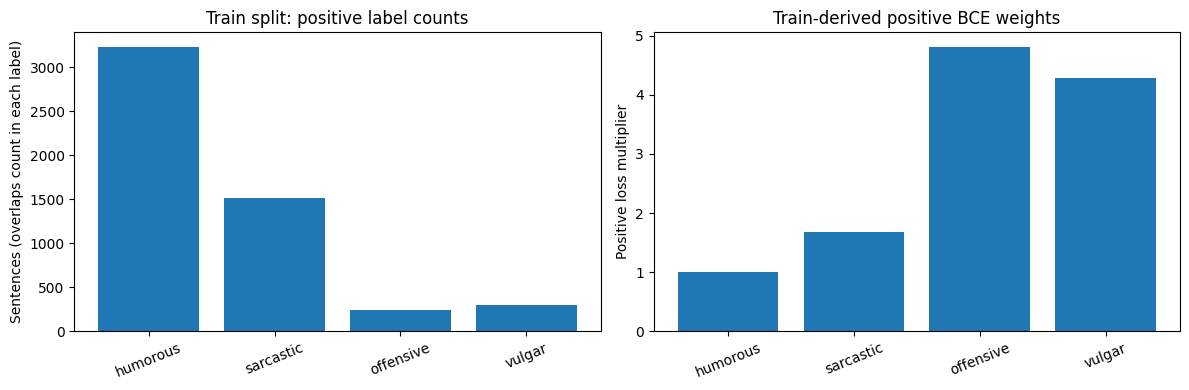

In [ ]:
train_label_matrix = train_df[LABELS].to_numpy(dtype=np.float32)
pos_counts = train_label_matrix.sum(axis=0)
neg_counts = len(train_df) - pos_counts
if np.any(pos_counts == 0):
    raise RuntimeError('A label has zero training positives; review the split before training.')
raw_ratio = neg_counts / pos_counts
train_pos_weights = np.clip(np.sqrt(raw_ratio), 1.0, POS_WEIGHT_CAP).astype(np.float32)
pos_weight_tensor = torch.tensor(train_pos_weights, dtype=torch.float32)

weight_table = pd.DataFrame({
    'label': LABELS, 'train_positive': pos_counts.astype(int),
    'train_negative': neg_counts.astype(int), 'raw_ratio': raw_ratio,
    'sqrt_clipped_pos_weight': train_pos_weights
})
weight_table.to_csv(TABLE_DIR / 'train_positive_weights.csv', index=False)
display(weight_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(LABELS, pos_counts)
axes[0].set_title('Train split: positive label counts')
axes[0].set_ylabel('Sentences (overlaps count in each label)')
axes[1].bar(LABELS, train_pos_weights)
axes[1].set_title('Train-derived positive BCE weights')
axes[1].set_ylabel('Positive loss multiplier')
for ax in axes:
    ax.tick_params(axis='x', rotation=22)
plt.tight_layout()
plt.savefig(FIG_DIR / 'training_imbalance_weights.png', dpi=200)
plt.show()

## Cell 6 — Tokenize once, prepare four-label examples, create encoder

BanglishBERT is an ELECTRA pretrained checkpoint; a new **four-logit classification head** is initialized automatically. New classification-head-weight warnings are expected. We use minimal text normalization so code-mixed spellings, punctuation, discourse particles and word elongation remain available to the model and SHAP.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, num_labels=len(LABELS), problem_type='multi_label_classification',
    id2label={i: name for i, name in enumerate(LABELS)},
    label2id={name: i for i, name in enumerate(LABELS)},
)

def build_hf_dataset(df):
    source = Dataset.from_pandas(df[['sentence'] + LABELS].reset_index(drop=True), preserve_index=False)
    def tokenize_batch(batch):
        features = tokenizer(batch['sentence'], max_length=MAX_LENGTH, truncation=True)
        features['labels'] = np.column_stack([batch[lab] for lab in LABELS]).astype(np.float32).tolist()
        return features
    return source.map(tokenize_batch, batched=True, remove_columns=['sentence'] + LABELS)

train_dataset = build_hf_dataset(train_df)
val_dataset = build_hf_dataset(val_df)
test_dataset = build_hf_dataset(test_df)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print('Tokenizer:', type(tokenizer).__name__)
print('Encoded example label vector:', train_dataset[0]['labels'])
print('Dataset sizes:', len(train_dataset), len(val_dataset), len(test_dataset))

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/874 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

...

Map:   0%|          | 0/5809 [00:00<?, ? examples/s]

Map:   0%|          | 0/1248 [00:00<?, ? examples/s]

Map:   0%|          | 0/1248 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Tokenizer: ElectraTokenizerFast
Encoded example label vector: [0.0, 1.0, 0.0, 0.0]
Dataset sizes: 5809 1248 1248


## Cell 7 — Weighted BCE Trainer, 15-epoch cap, 3-epoch early stopping

**Optimization:** weighted binary cross-entropy with logits (not softmax), AdamW, lr=2e-5, max length=128, effective single-GPU batch=32. **Best checkpoint** is picked by **validation macro average precision** (threshold-free). An epoch with no improvement in this metric counts toward patience=3. The run trains for **at most 15 epochs**, possibly fewer.

In [ ]:
class WeightedBCETrainer(Trainer):
    def __init__(self, *args, pos_weight, **kwargs):
        self.positive_weights = pos_weight.detach().clone()
        super().__init__(*args, **kwargs)
        # Trainer will scale gradient-accumulation micro-batch mean loss appropriately.
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        targets = inputs['labels'].float()
        model_inputs = {k: v for k, v in inputs.items() if k != 'labels'}
        outputs = model(**model_inputs)
        logits = outputs.logits.float()
        loss = F.binary_cross_entropy_with_logits(
            logits, targets, pos_weight=self.positive_weights.to(logits.device)
        )
        return (loss, outputs) if return_outputs else loss


def validation_ap_metric(eval_pred):
    logits, truths = eval_pred
    probs = expit(logits)
    aps = []
    for j in range(len(LABELS)):
        if len(np.unique(truths[:, j])) == 2:
            aps.append(average_precision_score(truths[:, j], probs[:, j]))
    return {'macro_ap': float(np.mean(aps)) if aps else 0.0}

bf16_supported = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
fp16_supported = torch.cuda.is_available() and not bf16_supported

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    num_train_epochs=NUM_EPOCHS,           # exactly the requested maximum: 15
    weight_decay=0.01,
    warmup_ratio=0.10,
    lr_scheduler_type='linear',
    optim='adamw_torch',
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_ap',
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    fp16=fp16_supported,
    bf16=bf16_supported,
    max_grad_norm=1.0,
    report_to='none',
)

trainer = WeightedBCETrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=validation_ap_metric,
    pos_weight=pos_weight_tensor,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)
print('Training set. Max epochs:', NUM_EPOCHS, 'Patience:', EARLY_STOPPING_PATIENCE)

Training set. Max epochs: 15 Patience: 3


## Cell 8 — **Start fine-tuning** and save the best checkpoint

This is the compute-intensive training cell. The Trainer evaluates and saves each epoch, automatically restores the best validation-Macro-AP checkpoint, and stores the trained model+tokenizer under `best_model/`. No test labels are accessed for training or checkpoint selection.

Epoch,Training Loss,Validation Loss,Macro Ap
1,0.676800,0.640257,0.255086
2,0.634300,0.624386,0.288331
3,0.607300,0.615074,0.304282
4,0.552800,0.640287,0.305148
5,0.490700,0.671209,0.312602
6,0.443900,0.713745,0.309196
7,0.406300,0.759356,0.315168
8,0.363200,0.767314,0.319917
9,0.330500,0.838449,0.309278
10,0.301200,0.869122,0.311749


{
  "run_id": "20261016T101524Z",
  "epochs_completed": 11.0,
  "best_model_checkpoint": "/content/drive/MyDrive/MixSarc_WeightedBCE_SHAP/20261016T101524Z/checkpoints/20261016T101524Z/checkpoint-1456",
  "best_validation_macro_ap": 0.31991651005056415,
  "early_stopping_patience": 3,
  "epochs_max": 15
}


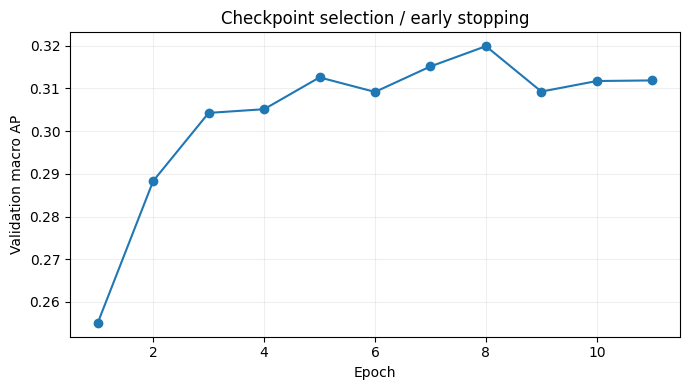

In [ ]:
train_output = trainer.train()
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

history_df = pd.DataFrame(trainer.state.log_history)
history_df.to_csv(TABLE_DIR / 'training_history.csv', index=False)
train_metadata = {
    'run_id': RUN_ID,
    'epochs_completed': float(trainer.state.epoch),
    'best_model_checkpoint': trainer.state.best_model_checkpoint,
    'best_validation_macro_ap': float(trainer.state.best_metric),
    'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'epochs_max': NUM_EPOCHS,
}
with open(ROOT / 'trained_model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(train_metadata, f, indent=2)
print(json.dumps(train_metadata, indent=2))

if 'eval_macro_ap' in history_df.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    eval_hist = history_df.dropna(subset=['eval_macro_ap'])
    ax.plot(eval_hist['epoch'], eval_hist['eval_macro_ap'], marker='o')
    ax.set(xlabel='Epoch', ylabel='Validation macro AP', title='Checkpoint selection / early stopping')
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'validation_macro_ap_by_epoch.png', dpi=200)
    plt.show()

## Cell 9 — Tune per-label thresholds **only on validation**

A 0.5 cutoff is not necessarily optimal for rare labels. For **each** of H/S/O/V independently, test candidate thresholds 0.05–0.95 (step 0.01) and choose the one maximizing validation F1; ties prefer the threshold **closest to 0.50**. The thresholds are then **frozen** for test inference. This is a selection procedure, not probability calibration.

In [ ]:
val_logits = trainer.predict(val_dataset).predictions
val_probs = expit(val_logits)
y_val = val_df[LABELS].to_numpy(dtype=int)

threshold_rows = []
thresholds = np.zeros(len(LABELS), dtype=float)

for j, label in enumerate(LABELS):
    scores = np.array([
        f1_score(y_val[:, j], (val_probs[:, j] >= t).astype(int), zero_division=0)
        for t in THRESHOLD_GRID
    ])
    best_f1 = scores.max()
    tied = THRESHOLD_GRID[np.isclose(scores, best_f1, rtol=0, atol=1e-12)]
    best_threshold = sorted(tied, key=lambda t: (abs(t - 0.50), t))[0]
    thresholds[j] = best_threshold
    threshold_rows.append({
        'label': label, 'positive_val_support': int(y_val[:, j].sum()),
        'threshold_selected': float(best_threshold),
        'validation_f1_at_0.50': float(f1_score(y_val[:, j],
                       (val_probs[:, j] >= 0.50).astype(int), zero_division=0)),
        'best_validation_f1': float(best_f1),
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df.to_csv(TABLE_DIR / 'validation_optimized_thresholds.csv', index=False)
with open(ROOT / 'thresholds.json', 'w', encoding='utf-8') as f:
    json.dump(dict(zip(LABELS, thresholds.tolist())), f, indent=2)
display(threshold_df.round(4))

,label,positive_val_support,threshold_selected,validation_f1_at_0.50,best_validation_f1
0,humorous,695,0.17,0.6751,0.7228
1,sarcastic,325,0.12,0.3477,0.4382
2,offensive,52,0.47,0.1263,0.1320
3,vulgar,66,0.47,0.3226,0.3313


## Cell 10 — Run one held-out test inference pass and export predictions

Keep the original four binary labels, four sigmoid probabilities, tuned-threshold predictions, **true/predicted exact combination**, and exact-match indicator. Example H+S means `[1,1,0,0]`; no separate H+S head exists. Do not revise the thresholds based on test results.

In [ ]:
test_logits = trainer.predict(test_dataset).predictions
test_probs = expit(test_logits)
y_true = test_df[LABELS].to_numpy(dtype=int)
y_pred = (test_probs >= thresholds[None, :]).astype(int)

prediction_df = test_df[['sentence_id', 'source_row_id', 'sentence']].copy().reset_index(drop=True)
for j, short in enumerate(SHORT_LABELS):
    prediction_df[f'true_{short}'] = y_true[:, j]
    prediction_df[f'prob_{short}'] = test_probs[:, j]
    prediction_df[f'threshold_{short}'] = thresholds[j]
    prediction_df[f'pred_{short}'] = y_pred[:, j]

prediction_df['true_combination'] = [labelset_name(vec) for vec in y_true]
prediction_df['pred_combination'] = [labelset_name(vec) for vec in y_pred]
prediction_df['true_num_labels'] = y_true.sum(axis=1)
prediction_df['pred_num_labels'] = y_pred.sum(axis=1)
prediction_df['is_multilabel_true'] = (prediction_df['true_num_labels'] >= 2).astype(int)
prediction_df['exact_match'] = np.all(y_true == y_pred, axis=1).astype(int)

prediction_df.to_csv(TABLE_DIR / 'test_predictions.csv', index=False)
display(prediction_df.head())
print('Test sentences:', len(prediction_df))
print('True multi-label sentences:', int(prediction_df['is_multilabel_true'].sum()))

,sentence_id,source_row_id,sentence,true_H,prob_H,threshold_H,pred_H,true_S,prob_S,threshold_S,...,true_V,prob_V,threshold_V,pred_V,true_combination,pred_combination,true_num_labels,pred_num_labels,is_multilabel_true,exact_match
0,1,1,shobai khela dekhtese ar ami tomar dp er dike ...,1,0.935346,0.17,1,0,0.156105,0.12,...,0,0.005911,0.47,0,H,H+S,1,2,0,0
1,2,2,sharadin bashay thakbo eta bhablei koto khushi...,1,0.322526,0.17,1,0,0.654011,0.12,...,0,0.007121,0.47,0,H,H+S,1,2,0,0
2,3,3,relationship ta boring hoye jacche abar jhogra...,0,0.822189,0.17,1,0,0.458106,0.12,...,0,0.005911,0.47,0,O,H+S,1,2,0,0
3,5,5,koi move on korar kotha ulta aro preme portesi,1,0.767690,0.17,1,0,0.437824,0.12,...,0,0.004468,0.47,0,H,H+S,1,2,0,0
4,9,9,stop thinking about that person and go to slee...,1,0.947381,0.17,1,0,0.122523,0.12,...,0,0.009708,0.47,0,H,H+S,1,2,0,0


Test sentences: 1248
True multi-label sentences: 156


## Cell 11 - Evaluation: per-label accuracy + overall exact-match accuracy

**Per-label** (one binary problem per output): precision, recall, F1, **accuracy**, average precision, TP/FP/FN/TN and positive support.

**Overall**: `accuracy` and `exact_match_accuracy` are the **same** number: a sentence is correct only if **all four** predicted labels match. `label_decision_accuracy = 1 - hamming_loss` reports the fraction of individual label decisions correct; it is **not** exact-match accuracy. Also report macro/micro/samples-F1 and Macro-AP. Binary accuracy can look artificially high for rare labels; F1, recall and AP remain essential.


In [ ]:
per_label_metrics = []
for j, label in enumerate(LABELS):
    truth, pred, prob = y_true[:, j], y_pred[:, j], test_probs[:, j]
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    ap = (average_precision_score(truth, prob)
          if np.unique(truth).size == 2 else np.nan)
    per_label_metrics.append({
        'label': label, 'test_positive_support': int(truth.sum()),
        'predicted_positive': int(pred.sum()),
        'precision': precision_score(truth, pred, zero_division=0),
        'recall': recall_score(truth, pred, zero_division=0),
        'f1': f1_score(truth, pred, zero_division=0),
        'accuracy': accuracy_score(truth, pred),
        'average_precision': ap,
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
    })
per_label_df = pd.DataFrame(per_label_metrics)
per_label_df.to_csv(TABLE_DIR / 'evaluation_per_label.csv', index=False)

overall_metrics = {
    'accuracy': accuracy_score(y_true, y_pred),  # exact match across all four labels
    'label_decision_accuracy': float(np.mean(y_true == y_pred)),
    'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
    'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
    'samples_f1_empty_empty_one': f1_score(y_true, y_pred, average='samples', zero_division=1),
    'exact_match_accuracy': accuracy_score(y_true, y_pred),
    'hamming_loss': hamming_loss(y_true, y_pred),
    'macro_average_precision': float(per_label_df['average_precision'].mean()),
    'test_support': int(len(y_true)),
}
overall_df = pd.DataFrame([overall_metrics])
overall_df.to_csv(TABLE_DIR / 'evaluation_overall.csv', index=False)

print('Per-label performance:')
display(per_label_df.round(4))
print('Overall multi-label performance:')
display(overall_df.round(4))

Per-label performance:


,label,test_positive_support,predicted_positive,precision,recall,f1,accuracy,average_precision,TP,FP,FN,TN
0,humorous,696,1094,0.5932,0.9325,0.7251,0.6058,0.6934,649,445,47,107
1,sarcastic,326,1018,0.2770,0.8650,0.4196,0.3750,0.3149,282,736,44,186
2,offensive,52,136,0.1103,0.2885,0.1596,0.8734,0.1126,15,121,37,1075
3,vulgar,65,109,0.2294,0.3846,0.2874,0.9006,0.2543,25,84,40,1099


Overall multi-label performance:


,accuracy,label_decision_accuracy,macro_f1,micro_f1,samples_f1_empty_empty_one,exact_match_accuracy,hamming_loss,macro_average_precision,test_support
0,0.1779,0.6887,0.3979,0.5555,0.5102,0.1779,0.3113,0.3438,1248


## Cell 12 — Evaluation B: exact label combinations **and** co-occurring pairs

- **Exact combination** H+S means **exactly** `[1,1,0,0]`. If the model predicts H+S+O, this is **not** an H+S exact match.
- **Co-occurring pair** H+S means **H and S are both active**, even if O/V are also active.

Evaluate **all 16 possible four-label patterns** (including NONE) so rare triple/quadruple cases are not forgotten. `test_support=0` ⇒ report P/R/F1 as **NaN** (not an invented zero). Very rare patterns have unstable estimates; always display support.

In [ ]:
exact_rows = []
for pattern in product([0, 1], repeat=4):
    vec = np.asarray(pattern, dtype=int)
    true_is_pattern = np.all(y_true == vec[None, :], axis=1).astype(int)
    pred_is_pattern = np.all(y_pred == vec[None, :], axis=1).astype(int)
    support = int(true_is_pattern.sum())
    pred_support = int(pred_is_pattern.sum())
    tp = int(np.logical_and(true_is_pattern, pred_is_pattern).sum())
    exact_rows.append({
        'combination': labelset_name(vec), 'test_support': support,
        'predicted_support': pred_support, 'TP': tp,
        'precision': precision_score(true_is_pattern, pred_is_pattern, zero_division=0)
                     if support > 0 else np.nan,
        'recall': recall_score(true_is_pattern, pred_is_pattern, zero_division=0)
                  if support > 0 else np.nan,
        'f1': f1_score(true_is_pattern, pred_is_pattern, zero_division=0)
              if support > 0 else np.nan,
    })
exact_combo_df = pd.DataFrame(exact_rows).sort_values(
    ['test_support', 'combination'], ascending=[False, True]
)
exact_combo_df.to_csv(TABLE_DIR / 'evaluation_combination_exact.csv', index=False)

pair_rows = []
for i, j in combinations(range(len(LABELS)), 2):
    actual_pair = (y_true[:, i] & y_true[:, j]).astype(int)
    predicted_pair = (y_pred[:, i] & y_pred[:, j]).astype(int)
    support = int(actual_pair.sum())
    pair_rows.append({
        'pair': SHORT_LABELS[i] + '+' + SHORT_LABELS[j], 'test_support': support,
        'predicted_support': int(predicted_pair.sum()),
        'precision': precision_score(actual_pair, predicted_pair, zero_division=0) if support else np.nan,
        'recall': recall_score(actual_pair, predicted_pair, zero_division=0) if support else np.nan,
        'f1': f1_score(actual_pair, predicted_pair, zero_division=0) if support else np.nan,
    })
pair_df = pd.DataFrame(pair_rows)
pair_df.to_csv(TABLE_DIR / 'evaluation_pair_cooccurrence.csv', index=False)

print('Exact-pattern performance:')
display(exact_combo_df.round(3))
print('Pair co-occurrence performance:')
display(pair_df.round(3))

Exact-pattern performance:


,combination,test_support,predicted_support,TP,precision,recall,f1
8,H,555,185,108,0.584,0.195,0.292
0,NONE,267,0,0,0.000,0.000,0.000
4,S,200,113,31,0.274,0.155,0.198
12,H+S,115,798,83,0.104,0.722,0.182
1,V,41,0,0,0.000,0.000,0.000
2,O,29,0,0,0.000,0.000,0.000
9,H+V,14,0,0,0.000,0.000,0.000
10,H+O,11,17,0,0.000,0.000,0.000
3,O+V,5,0,0,0.000,0.000,0.000
6,S+O,5,1,0,0.000,0.000,0.000


Pair co-occurrence performance:


,pair,test_support,predicted_support,precision,recall,f1
0,H+S,116,864,0.103,0.767,0.182
1,H+O,12,111,0.027,0.250,0.049
2,H+V,14,69,0.058,0.286,0.096
3,S+O,7,91,0.000,0.000,0.000
4,S+V,5,81,0.025,0.400,0.047
5,O+V,6,93,0.043,0.667,0.081


## Cell 13 — Export test evaluation charts

Charts use only held-out test results and are descriptive. Compare per-label F1/AP with the exact-combination recall support (where nonzero).

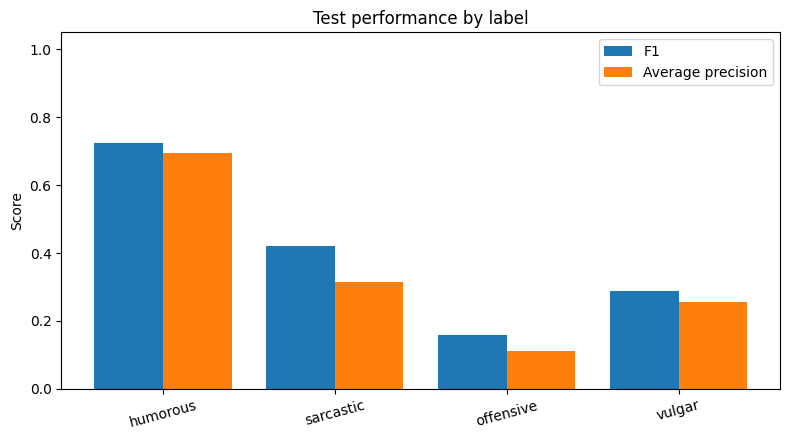

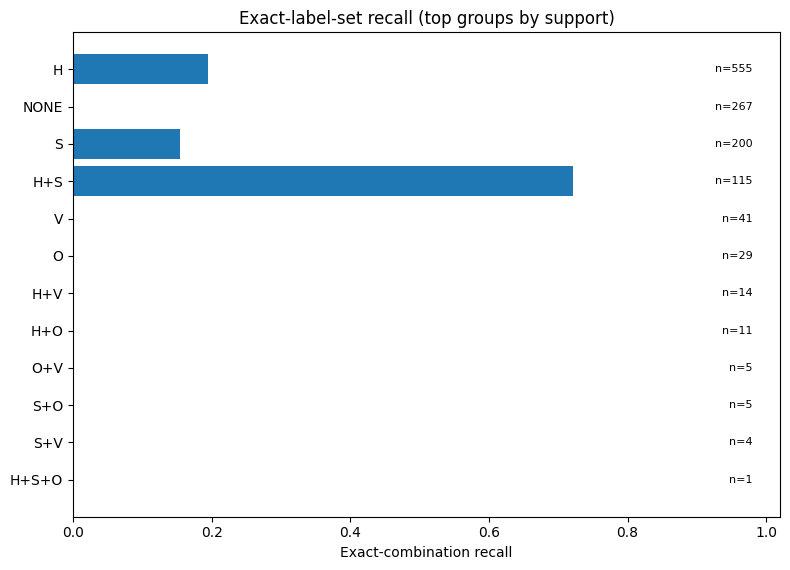

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(LABELS))
ax.bar(x - 0.2, per_label_df['f1'], width=0.4, label='F1')
ax.bar(x + 0.2, per_label_df['average_precision'], width=0.4, label='Average precision')
ax.set_xticks(x, labels=LABELS, rotation=15)
ax.set_ylim(0, 1.05)
ax.set_title('Test performance by label')
ax.set_ylabel('Score')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'test_per_label_f1_ap.png', dpi=200)
plt.show()

visible = exact_combo_df[exact_combo_df['test_support'] > 0].head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, max(4, 0.4 * len(visible) + 1)))
ax.barh(visible['combination'], visible['recall'].fillna(0))
ax.set_xlim(0, 1.02)
ax.set_xlabel('Exact-combination recall')
ax.set_title('Exact-label-set recall (top groups by support)')
for i, support in enumerate(visible['test_support']):
    ax.text(0.98, i, f'n={support}', ha='right', va='center', fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'test_exact_combination_recall.png', dpi=200)
plt.show()

## Cell 14 — SHAP design: all four outputs for **every** test sentence

We explain **sigmoid probabilities** with a custom Unicode **word + punctuation** tokenizer for SHAP masking. Importantly, the model prediction function still uses the **original BanglishBERT tokenizer** internally; word/punctuation segments are the **explanation units**, not transformer subword IDs. The masked text uses the model's `[MASK]` token.

For each test sentence with \(m\) visible text segments, SHAP returns an \(m\times4\) matrix, **including** negative outputs. Multi-label sentences and misclassified examples are **all included**.

SHAP attribution uses masking-based baselines and is **not a linguistic ground-truth detector**. Exact masking choices should be stated in your paper. Run the next small sanity check before the expensive full test extraction.

In [ ]:
import shap

best_model = trainer.model
best_model.eval()
predict_device = next(best_model.parameters()).device

# The function returns sigmoid scores in the fixed [H, S, O, V] order.
def shap_predict_proba(texts):
    if isinstance(texts, str):
        texts = [texts]
    text_list = [str(t) for t in texts]
    if not text_list:
        return np.empty((0, len(LABELS)), dtype=float)
    chunks = []
    for start in range(0, len(text_list), EVAL_BATCH_SIZE):
        batch = tokenizer(
            text_list[start:start + EVAL_BATCH_SIZE],
            padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors='pt'
        ).to(predict_device)
        with torch.inference_mode():
            logits = best_model(**batch).logits.float()
            chunks.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(chunks, axis=0)

# Each Unicode word or punctuation mark is its own SHAP segment.
WORD_PUNCT_RE = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)
def shap_word_punct_tokenizer(s, return_offsets_mapping=True):
    matches = list(WORD_PUNCT_RE.finditer(str(s)))
    result = {'input_ids': [m.group(0) for m in matches]}
    if return_offsets_mapping:
        result['offset_mapping'] = [m.span() for m in matches]
    return result

masker = shap.maskers.Text(
    shap_word_punct_tokenizer,
    mask_token=tokenizer.mask_token or '[MASK]',
    collapse_mask_token=True,
)
explainer = shap.Explainer(
    shap_predict_proba, masker, algorithm='partition', output_names=LABELS, seed=SEED
)

# Choose a real H+S test example if present, otherwise take the first test example.
examples_hs = prediction_df[prediction_df['true_combination'] == 'H+S']
demo_record = examples_hs.iloc[0] if len(examples_hs) else prediction_df.iloc[0]
demo_sentence, demo_id = demo_record['sentence'], int(demo_record['sentence_id'])

probe = explainer([demo_sentence], max_evals=SHAP_MAX_EVALS, batch_size=SHAP_BATCH_SIZE)
probe_tokens = [str(s).strip() for s in probe.data[0]]
probe_values = np.asarray(probe.values[0], dtype=float)
probe_base = np.asarray(probe.base_values[0], dtype=float)
probe_actual = shap_predict_proba([demo_sentence])[0]
reconstruction = probe_base + probe_values.sum(axis=0)
assert probe_values.shape == (len(probe_tokens), len(LABELS))
print('Demo sentence:', demo_sentence)
print('SHAP segments:', probe_tokens)
print('SHAP additivity absolute error (per output):', np.abs(probe_actual - reconstruction))

probe_table = pd.DataFrame(probe_values, columns=SHAP_COLUMNS)
probe_table.insert(0, 'token', probe_tokens)
display(probe_table.round(5))
shap.plots.text(probe[0, :, 1])     # Sarcastic explanation; select another output index as needed

Demo sentence: pura jibon ta eto baal gese ami purano din gula miss o korina
SHAP segments: ['pura', 'jibon', 'ta', 'eto', 'baal', 'gese', 'ami', 'purano', 'din', 'gula', 'miss', 'o', 'korina']
SHAP additivity absolute error (per output): [0. 0. 0. 0.]


,token,Humor_SHAP,Sarcasm_SHAP,Offensive_SHAP,Vulgar_SHAP
0,pura,0.04439,0.17384,-0.01874,-0.02111
1,jibon,0.26470,-0.11790,0.00953,-0.00844
2,ta,-0.07591,0.06641,-0.00057,0.00459
3,eto,-0.01537,0.05569,0.00474,0.00703
4,baal,0.16193,-0.10543,0.00334,0.00122
5,gese,0.05747,-0.03445,0.00578,0.00364
6,ami,-0.07348,0.05862,0.00502,0.00477
7,purano,0.14649,-0.09552,0.00512,0.00170
8,din,-0.03699,0.03616,-0.00684,-0.00144
9,gula,-0.05443,0.05277,0.00071,0.00097


## Cell 15 - Export `shap_local_wide.csv` (complete SHAP archive)

One row = **one token/punctuation segment in one test sentence**, with `sentence_id`, `token_position`, `token`, `token_segment_raw`, `token_normalized`, and four signed contributions:
`Humor_SHAP`, `Sarcasm_SHAP`, `Offensive_SHAP`, `Vulgar_SHAP`.

All four explanations are retained for **all explained test sentences** (even predicted-negative heads) for future false-negative investigations. Write resumable chunks to disk; final CSV is assembled after verifying coverage. A separate **JSON** file stores SHAP baseline/additivity QA metadata. The filtered `sentence_level_shap.csv` is built in the next cell **without running SHAP again**.


In [ ]:
from tqdm.auto import tqdm

if SHAP_LIMIT is None:
    explain_df = prediction_df.copy()
else:
    if SHAP_LIMIT <= 0:
        raise ValueError('SHAP_LIMIT must be None or positive.')
    explain_df = prediction_df.iloc[:int(SHAP_LIMIT)].copy()

print('SHAP sentences requested:', len(explain_df), 'of', len(prediction_df))
print('Chunk directory:', SHAP_PARTS_DIR)

for start in tqdm(range(0, len(explain_df), SHAP_CHUNK_SIZE), desc='SHAP chunks'):
    stop = min(start + SHAP_CHUNK_SIZE, len(explain_df))
    part_wide = SHAP_PARTS_DIR / f'chunk_{start:06d}_{stop:06d}_wide.csv'
    part_meta = SHAP_PARTS_DIR / f'chunk_{start:06d}_{stop:06d}_meta.csv'

    if part_wide.exists() and part_meta.exists():
        continue  # safely reuse completed chunks for this RUN_ID

    wide_rows, sentence_rows = [], []
    for _, rec in explain_df.iloc[start:stop].iterrows():
        text = str(rec['sentence'])
        sid = int(rec['sentence_id'])
        explanation = explainer([text], max_evals=SHAP_MAX_EVALS, batch_size=SHAP_BATCH_SIZE)
        token_segs = list(explanation.data[0])
        scores = np.asarray(explanation.values[0], dtype=float)
        bases = np.asarray(explanation.base_values[0], dtype=float).reshape(-1)
        if scores.shape != (len(token_segs), 4) or bases.shape != (4,):
            raise RuntimeError(f'Unexpected SHAP shape for sentence {sid}: {scores.shape}, {bases.shape}')

        actual_scores = np.array([float(rec[f'prob_{s}']) for s in SHORT_LABELS])
        reconstructed = bases + scores.sum(axis=0)
        check_row = {
            'sentence_id': sid, 'true_combination': rec['true_combination'],
            'pred_combination': rec['pred_combination'],
            'max_abs_additivity_error': float(np.abs(reconstructed - actual_scores).max()),
        }
        for j, short in enumerate(SHORT_LABELS):
            check_row[f'base_{short}'] = float(bases[j])
            check_row[f'prob_{short}'] = float(actual_scores[j])
            check_row[f'reconstructed_prob_{short}'] = float(reconstructed[j])
        sentence_rows.append(check_row)

        for pos, raw_segment in enumerate(token_segs):
            clean_segment = str(raw_segment).strip()
            wide_rows.append({
                'sentence_id': sid, 'token_position': int(pos),
                'token': clean_segment, 'token_segment_raw': str(raw_segment),
                'token_normalized': clean_segment.casefold(),
                **{SHAP_COLUMNS[j]: float(scores[pos, j]) for j in range(4)},
            })

    # Atomic replacement: partial writes won't be mistaken for completed chunks.
    tmp_wide = part_wide.with_suffix('.tmp')
    tmp_meta = part_meta.with_suffix('.tmp')
    pd.DataFrame(wide_rows).to_csv(tmp_wide, index=False)
    pd.DataFrame(sentence_rows).to_csv(tmp_meta, index=False)
    os.replace(tmp_wide, part_wide)
    os.replace(tmp_meta, part_meta)

wide_parts = sorted(SHAP_PARTS_DIR.glob('chunk_*_wide.csv'))
meta_parts = sorted(SHAP_PARTS_DIR.glob('chunk_*_meta.csv'))
if not wide_parts or len(wide_parts) != len(meta_parts):
    raise RuntimeError('Missing one or more SHAP chunk outputs; investigate before aggregating.')

shap_wide = pd.concat([pd.read_csv(p, keep_default_na=False) for p in wide_parts], ignore_index=True)
shap_sentence_meta = pd.concat([pd.read_csv(p) for p in meta_parts], ignore_index=True)
if set(shap_sentence_meta['sentence_id']) != set(explain_df['sentence_id']):
    raise RuntimeError('SHAP coverage mismatch: not every requested test sentence was explained.')

shap_wide.to_csv(TABLE_DIR / 'shap_local_wide.csv', index=False, float_format='%.12g')
shap_sentence_meta.to_json(ROOT / 'shap_sentence_metadata.json', orient='records', indent=2)

max_additivity_error = float(shap_sentence_meta['max_abs_additivity_error'].max())
print('Saved wide token rows:', len(shap_wide))
print('Explained sentences:', shap_sentence_meta['sentence_id'].nunique())
print('Maximum absolute SHAP additivity error:', max_additivity_error)
if max_additivity_error > 0.02:
    warnings.warn('Large SHAP additivity discrepancy; verify masker, prediction function and truncation.')
display(shap_wide.head(12))

SHAP sentences requested: 1248 of 1248
Chunk directory: /content/drive/MyDrive/MixSarc_WeightedBCE_SHAP/20261016T101524Z/shap_parts/20261016T101524Z


SHAP chunks:   0%|          | 0/125 [00:00<?, ?it/s]

Saved wide token rows: 15838
Explained sentences: 1248
Maximum absolute SHAP additivity error: 0.0205939412117004


/tmp/ipykernel_2029/4176539188.py:80: UserWarning: Large SHAP additivity discrepancy; verify masker, prediction function and truncation.
  warnings.warn('Large SHAP additivity discrepancy; verify masker, prediction function and truncation.')


,sentence_id,token_position,token,token_segment_raw,token_normalized,Humor_SHAP,Sarcasm_SHAP,Offensive_SHAP,Vulgar_SHAP
0,1,0,shobai,shobai,shobai,0.182850,0.016412,-0.071627,-0.039593
1,1,1,khela,khela,khela,0.155107,-0.020443,-0.002624,-0.008007
2,1,2,dekhtese,dekhtese,dekhtese,0.205715,-0.028715,-0.034587,-0.047400
3,1,3,ar,ar,ar,-0.005560,0.008363,0.064872,0.040828
4,1,4,ami,ami,ami,-0.064623,0.057611,0.004942,0.007919
5,1,5,tomar,tomar,tomar,0.010760,-0.080372,0.014184,0.014564
6,1,6,dp,dp,dp,-0.047767,0.027637,0.006719,0.011185
7,1,7,er,er,er,0.020332,0.011392,-0.002845,-0.009028
8,1,8,dike,dike,dike,-0.006310,0.000972,0.006038,0.007445
9,1,9,takay,takay,takay,0.139833,-0.008187,0.004036,0.000756


## Cell 16 - Export `sentence_level_shap.csv` (predicted-positive explanations only)

We reshape the complete wide archive **in memory** and match each label to its original test ground truth, tuned prediction and **actual predicted probability**. Select only rows where the corresponding output has `predicted_label=1`.

The output contains **exactly 10 columns in the requested order**:

1. `sentence_id`
2. `sentence`
3. `token_index` (SHAP text-segment index; includes punctuation)
4. `token`
5. `shap_target_label` (`Humorous`, `Sarcastic`, `Offensive`, `Vulgar`)
6. `gold_label` (0/1 for the explained head)
7. `predicted_label` (always 1 here)
8. `predicted_probability` (sigmoid score for that head)
9. `shap_value` (signed probability attribution)
10. `abs_shap_value` (absolute magnitude)

For a sentence predicted as H+S, each token will have **two** rows (one per predicted-positive label). A sentence with no positive predictions has no rows here but still appears in `test_predictions.csv` and `shap_local_wide.csv`.


In [ ]:
# Reshape wide scores in memory; do not export a redundant long CSV.
shap_long = shap_wide.melt(
    id_vars=['sentence_id', 'token_position', 'token', 'token_normalized'],
    value_vars=SHAP_COLUMNS, var_name='shap_column', value_name='shap_value'
)
reverse_shap_map = {v: k for k, v in LABEL_TO_SHAP_COLUMN.items()}
shap_long['target_label'] = shap_long['shap_column'].map(reverse_shap_map)
merge_cols = ['sentence_id', 'sentence', 'true_combination', 'pred_combination', 'exact_match']
merge_cols += [f'true_{s}' for s in SHORT_LABELS]
merge_cols += [f'pred_{s}' for s in SHORT_LABELS]
merge_cols += [f'prob_{s}' for s in SHORT_LABELS]
shap_long = shap_long.merge(prediction_df[merge_cols], on='sentence_id', validate='many_to_one')

shap_long['true_label'] = 0
shap_long['pred_label'] = 0
shap_long['predicted_probability'] = np.nan
for label, short in zip(LABELS, SHORT_LABELS):
    mask = shap_long['target_label'].eq(label)
    shap_long.loc[mask, 'true_label'] = shap_long.loc[mask, f'true_{short}'].to_numpy()
    shap_long.loc[mask, 'pred_label'] = shap_long.loc[mask, f'pred_{short}'].to_numpy()
    shap_long.loc[mask, 'predicted_probability'] = shap_long.loc[mask, f'prob_{short}'].to_numpy()

shap_long['prediction_status'] = np.select([
    shap_long.true_label.eq(1) & shap_long.pred_label.eq(1),
    shap_long.true_label.eq(0) & shap_long.pred_label.eq(1),
    shap_long.true_label.eq(1) & shap_long.pred_label.eq(0),
], ['TP', 'FP', 'FN'], default='TN')
shap_long['shap_value'] = pd.to_numeric(shap_long['shap_value'], errors='raise')

# Main researcher-friendly sentence-level file: predicted-positive heads only.
sentence_level = shap_long.loc[shap_long['pred_label'].eq(1)].copy()
sentence_level['shap_target_label'] = sentence_level['target_label'].str.title()
sentence_level['token_index'] = sentence_level['token_position'].astype(int)
sentence_level['gold_label'] = sentence_level['true_label'].astype(int)
sentence_level['predicted_label'] = sentence_level['pred_label'].astype(int)
sentence_level['abs_shap_value'] = sentence_level['shap_value'].abs()
SENTENCE_LEVEL_COLUMNS = [
    'sentence_id', 'sentence', 'token_index', 'token', 'shap_target_label',
    'gold_label', 'predicted_label', 'predicted_probability',
    'shap_value', 'abs_shap_value',
]
sentence_level = sentence_level[SENTENCE_LEVEL_COLUMNS].sort_values(
    ['sentence_id', 'shap_target_label', 'token_index'], kind='mergesort'
).reset_index(drop=True)
sentence_level.to_csv(TABLE_DIR / 'sentence_level_shap.csv', index=False, float_format='%.12g')
assert sentence_level['predicted_label'].eq(1).all()
assert np.allclose(sentence_level['abs_shap_value'], sentence_level['shap_value'].abs())
print('Complete SHAP token rows:', len(shap_wide))
print('Predicted-positive label/token rows:', len(sentence_level))
print('Predicted-positive label explanations:', sentence_level.groupby(
    ['sentence_id', 'shap_target_label']).ngroups)
display(sentence_level.head(14))


Complete SHAP token rows: 15838
Predicted-positive label/token rows: 30555
Predicted-positive label explanations: 2357


,sentence_id,sentence,token_index,token,shap_target_label,gold_label,predicted_label,predicted_probability,shap_value,abs_shap_value
0,1,shobai khela dekhtese ar ami tomar dp er dike ...,0,shobai,Humorous,1,1,0.935346,0.182850,0.182850
1,1,shobai khela dekhtese ar ami tomar dp er dike ...,1,khela,Humorous,1,1,0.935346,0.155107,0.155107
2,1,shobai khela dekhtese ar ami tomar dp er dike ...,2,dekhtese,Humorous,1,1,0.935346,0.205715,0.205715
3,1,shobai khela dekhtese ar ami tomar dp er dike ...,3,ar,Humorous,1,1,0.935346,-0.005560,0.005560
4,1,shobai khela dekhtese ar ami tomar dp er dike ...,4,ami,Humorous,1,1,0.935346,-0.064623,0.064623
5,1,shobai khela dekhtese ar ami tomar dp er dike ...,5,tomar,Humorous,1,1,0.935346,0.010760,0.010760
6,1,shobai khela dekhtese ar ami tomar dp er dike ...,6,dp,Humorous,1,1,0.935346,-0.047767,0.047767
7,1,shobai khela dekhtese ar ami tomar dp er dike ...,7,er,Humorous,1,1,0.935346,0.020332,0.020332
8,1,shobai khela dekhtese ar ami tomar dp er dike ...,8,dike,Humorous,1,1,0.935346,-0.006310,0.006310
9,1,shobai khela dekhtese ar ami tomar dp er dike ...,9,takay,Humorous,1,1,0.935346,0.139833,0.139833


## Cell 17 - Export `label_wise_top_tokens.csv` (12 requested columns)

**One row = one normalized token for one target label and one analysis scope.** Scopes: `predicted_positive` (**main paper charts**), `all_test` (complete archive), `actual_positive`, `TP`, `FP`, and `FN` (error analysis). The primary `predicted_positive` scope includes **both TP and FP** predictions; this is intentionally broader than TP-only charts for rare Offensive/Vulgar labels.

**Requested 12 columns:** `target_label`, `rank`, `token`, `token_occurrence_count`, `unique_sentence_count`, `mean_abs_shap`, `mean_signed_shap`, `positive_shap_count`, `negative_shap_count`, `positive_shap_rate`, `negative_shap_rate`, `analysis_scope`.

- A **token occurrence** means one SHAP text segment row, even if the same token appears twice in a sentence. `unique_sentence_count` counts the sentence only once. Means are **per occurrence** so they match the counts; repeated tokens are *not* aggregated before taking these means.
- `rank=1` is highest **mean absolute SHAP** within the `(target_label, analysis_scope)` group. Ties break by number of sentences then token string; this **importance ranking is not a positive-only or negative-only ranking**.
- `positive_shap_rate = positive_shap_count / token_occurrence_count`, and likewise negative. Zero-SHAP occurrences count toward the denominator but neither sign count.
- For positive/negative charts we rank separately by **mean signed SHAP**, after applying the configured minimum sentence frequency.


In [ ]:
# Keep the sentence-level aggregation helper for the optional in-memory H+S comparison.
def aggregate_sentence_tokens(frame, group_cols):
    """SUM repeated token contributions per sentence; then average across sentences."""
    if frame.empty:
        return pd.DataFrame()
    cols = group_cols + ['token_normalized', 'sentence_id']
    per_sentence = frame.groupby(cols, as_index=False, dropna=False)['shap_value'].sum()
    per_sentence['abs_score'] = per_sentence['shap_value'].abs()
    per_sentence['positive_part'] = per_sentence['shap_value'].clip(lower=0)
    per_sentence['negative_part'] = per_sentence['shap_value'].clip(upper=0)
    per_sentence['positive_flag'] = per_sentence['shap_value'].gt(0).astype(float)
    return (per_sentence.groupby(group_cols + ['token_normalized'], as_index=False, dropna=False)
            .agg(n_sentences=('sentence_id', 'nunique'),
                 mean_SHAP=('shap_value', 'mean'),
                 mean_abs_SHAP=('abs_score', 'mean'),
                 mean_positive_SHAP=('positive_part', 'mean'),
                 mean_negative_SHAP=('negative_part', 'mean'),
                 positive_rate=('positive_flag', 'mean'))
            .rename(columns={'token_normalized': 'token'}))

scope_masks = {
    'predicted_positive': shap_long['pred_label'].eq(1),
    'all_test': pd.Series(True, index=shap_long.index),
    'actual_positive': shap_long['true_label'].eq(1),
    'TP': shap_long['prediction_status'].eq('TP'),
    'FP': shap_long['prediction_status'].eq('FP'),
    'FN': shap_long['prediction_status'].eq('FN'),
}
parts = []
for scope, mask in scope_masks.items():
    selected = shap_long.loc[mask, [
        'sentence_id', 'token_normalized', 'target_label', 'shap_value'
    ]].copy()
    selected['analysis_scope'] = scope
    selected['abs_shap'] = selected['shap_value'].abs()
    selected['positive_flag'] = selected['shap_value'].gt(0).astype(int)
    selected['negative_flag'] = selected['shap_value'].lt(0).astype(int)
    parts.append(selected)
all_scope_tokens = pd.concat(parts, ignore_index=True)
all_scope_tokens = all_scope_tokens[
    all_scope_tokens['token_normalized'].astype(str).str.len().gt(0)
].copy()

top_tokens = (all_scope_tokens.groupby(
    ['target_label', 'analysis_scope', 'token_normalized'],
    dropna=False, as_index=False
).agg(
    token_occurrence_count=('shap_value', 'size'),
    unique_sentence_count=('sentence_id', 'nunique'),
    mean_abs_shap=('abs_shap', 'mean'),
    mean_signed_shap=('shap_value', 'mean'),
    positive_shap_count=('positive_flag', 'sum'),
    negative_shap_count=('negative_flag', 'sum'),
))
top_tokens['positive_shap_rate'] = (
    top_tokens['positive_shap_count'] / top_tokens['token_occurrence_count']
)
top_tokens['negative_shap_rate'] = (
    top_tokens['negative_shap_count'] / top_tokens['token_occurrence_count']
)
top_tokens = top_tokens.rename(columns={'token_normalized': 'token'})
top_tokens['target_label'] = top_tokens['target_label'].str.title()
top_tokens = top_tokens.sort_values(
    ['target_label', 'analysis_scope', 'mean_abs_shap', 'unique_sentence_count', 'token'],
    ascending=[True, True, False, False, True], kind='mergesort'
)
top_tokens['rank'] = top_tokens.groupby(
    ['target_label', 'analysis_scope'], sort=False
).cumcount() + 1
TOKEN_SUMMARY_COLUMNS = [
    'target_label', 'rank', 'token', 'token_occurrence_count',
    'unique_sentence_count', 'mean_abs_shap', 'mean_signed_shap',
    'positive_shap_count', 'negative_shap_count',
    'positive_shap_rate', 'negative_shap_rate', 'analysis_scope',
]
top_tokens = top_tokens[TOKEN_SUMMARY_COLUMNS].reset_index(drop=True)
top_tokens.to_csv(TABLE_DIR / 'label_wise_top_tokens.csv', index=False, float_format='%.12g')
assert top_tokens['rank'].ge(1).all()
assert (top_tokens['positive_shap_count'] + top_tokens['negative_shap_count'] <=
        top_tokens['token_occurrence_count']).all()
print('Token summary rows:', len(top_tokens))
print('Analysis scopes:', sorted(top_tokens['analysis_scope'].unique()))
display(top_tokens.query('target_label == "Sarcastic" and analysis_scope == "predicted_positive"').head(12))


Token summary rows: 40707
Analysis scopes: ['FN', 'FP', 'TP', 'actual_positive', 'all_test', 'predicted_positive']


,target_label,rank,token,token_occurrence_count,unique_sentence_count,mean_abs_shap,mean_signed_shap,positive_shap_count,negative_shap_count,positive_shap_rate,negative_shap_rate,analysis_scope
31338,Sarcastic,1,fuckboy,1,1,0.407062,-0.407062,0,1,0.0,1.0,predicted_positive
31339,Sarcastic,2,bujhlm,1,1,0.386901,0.386901,1,0,1.0,0.0,predicted_positive
31340,Sarcastic,3,potaia,1,1,0.369417,0.369417,1,0,1.0,0.0,predicted_positive
31341,Sarcastic,4,rastai,1,1,0.369213,0.369213,1,0,1.0,0.0,predicted_positive
31342,Sarcastic,5,bujhtechi,1,1,0.368654,0.368654,1,0,1.0,0.0,predicted_positive
31343,Sarcastic,6,mainser,1,1,0.362402,0.362402,1,0,1.0,0.0,predicted_positive
31344,Sarcastic,7,chakma,1,1,0.359006,0.359006,1,0,1.0,0.0,predicted_positive
31345,Sarcastic,8,permission,1,1,0.354938,0.354938,1,0,1.0,0.0,predicted_positive
31346,Sarcastic,9,oufff,1,1,0.338766,0.338766,1,0,1.0,0.0,predicted_positive
31347,Sarcastic,10,bhallagto,1,1,0.335029,0.335029,1,0,1.0,0.0,predicted_positive


## Cell 18 - Optional in-memory label-combination comparison

To keep the **three requested primary SHAP CSVs** as the only exported SHAP tables, the exact H+S / O+V combination summary is computed **in memory** but not exported as an extra SHAP CSV. It can be regenerated from `shap_local_wide.csv` and `test_predictions.csv` any time. Grouping uses the **true exact label combination**; each output head is explained separately (do not add Humor and Sarcasm SHAP to invent a new output).


In [ ]:
combo_subset_parts = []
for subset_name in ['all_test', 'actual_positive', 'TP']:
    if subset_name == 'all_test':
        mask = pd.Series(True, index=shap_long.index)
    elif subset_name == 'actual_positive':
        mask = shap_long['true_label'].eq(1)
    else:
        mask = shap_long['prediction_status'].eq('TP')
    part = shap_long.loc[mask, [
        'sentence_id', 'token_normalized', 'target_label', 'true_combination', 'shap_value'
    ]].copy()
    part['analysis_subset'] = subset_name
    combo_subset_parts.append(part)

combo_subset_data = pd.concat(combo_subset_parts, ignore_index=True)
combo_subset_data = combo_subset_data.rename(columns={'true_combination': 'combination'})

global_combination = aggregate_sentence_tokens(
    combo_subset_data, ['combination', 'analysis_subset', 'target_label']
)
combination_test_support = prediction_df['true_combination'].value_counts().to_dict()
global_combination['combination_test_support'] = global_combination['combination'].map(
    combination_test_support
)
global_combination = global_combination.sort_values(
    ['combination', 'analysis_subset', 'target_label', 'mean_abs_SHAP'],
    ascending=[True, True, True, False]
)
print('Global combination-label-token rows:', len(global_combination))
display(global_combination.query("combination == 'H+S' and analysis_subset == 'all_test'").head(12))

Global combination-label-token rows: 37901


,combination,analysis_subset,target_label,token,n_sentences,mean_SHAP,mean_abs_SHAP,mean_positive_SHAP,mean_negative_SHAP,positive_rate,combination_test_support
18595,H+S,all_test,humorous,expose,1,0.493541,0.493541,0.493541,0.000000,1.0,115
18682,H+S,all_test,humorous,introvert,1,0.463801,0.463801,0.463801,0.000000,1.0,115
18558,H+S,all_test,humorous,dosh,1,0.462189,0.462189,0.462189,0.000000,1.0,115
18912,H+S,all_test,humorous,ordekh,1,0.437232,0.437232,0.437232,0.000000,1.0,115
18512,H+S,all_test,humorous,concert,1,0.421105,0.421105,0.421105,0.000000,1.0,115
18456,H+S,all_test,humorous,block,1,0.415631,0.415631,0.415631,0.000000,1.0,115
18706,H+S,all_test,humorous,jhogra,1,0.411739,0.411739,0.411739,0.000000,1.0,115
19050,H+S,all_test,humorous,sun,1,-0.404445,0.404445,0.000000,-0.404445,0.0,115
19009,H+S,all_test,humorous,sharee,1,0.401853,0.401853,0.401853,0.000000,1.0,115
18628,H+S,all_test,humorous,ghosted,1,0.396847,0.396847,0.396847,0.000000,1.0,115


## Cell 19 - Four label-wise figures (one figure per label, positive + negative panels)

Create **one figure for each of the four labels**: `Humorous`, `Sarcastic`, `Offensive`, and `Vulgar`. **Each single figure contains two side-by-side panels**:

- **Left:** Top 10 positive contributors, highest **positive** `mean_signed_shap`.
- **Right:** Top 10 negative contributors, most **negative** `mean_signed_shap`.

Both panels use **held-out test sentences only**, with `analysis_scope = predicted_positive` (true-positive + false-positive predictions for that label). Each token must appear in at least `MIN_TOKEN_SENTENCES` distinct test sentences (default 3). If a direction has fewer than 10 eligible tokens, show the available number without inventing results. Each panel is **independently scaled** to make smaller negative contributions visible; compare the numeric SHAP values across panels, not bar lengths.

**Output: exactly four PNGs** named `top10_contributors_humorous.png`, `top10_contributors_sarcastic.png`, `top10_contributors_offensive.png`, and `top10_contributors_vulgar.png`. The single `rank` column in `label_wise_top_tokens.csv` still uses **mean absolute SHAP**; the directional panel rankings use **mean signed SHAP**.


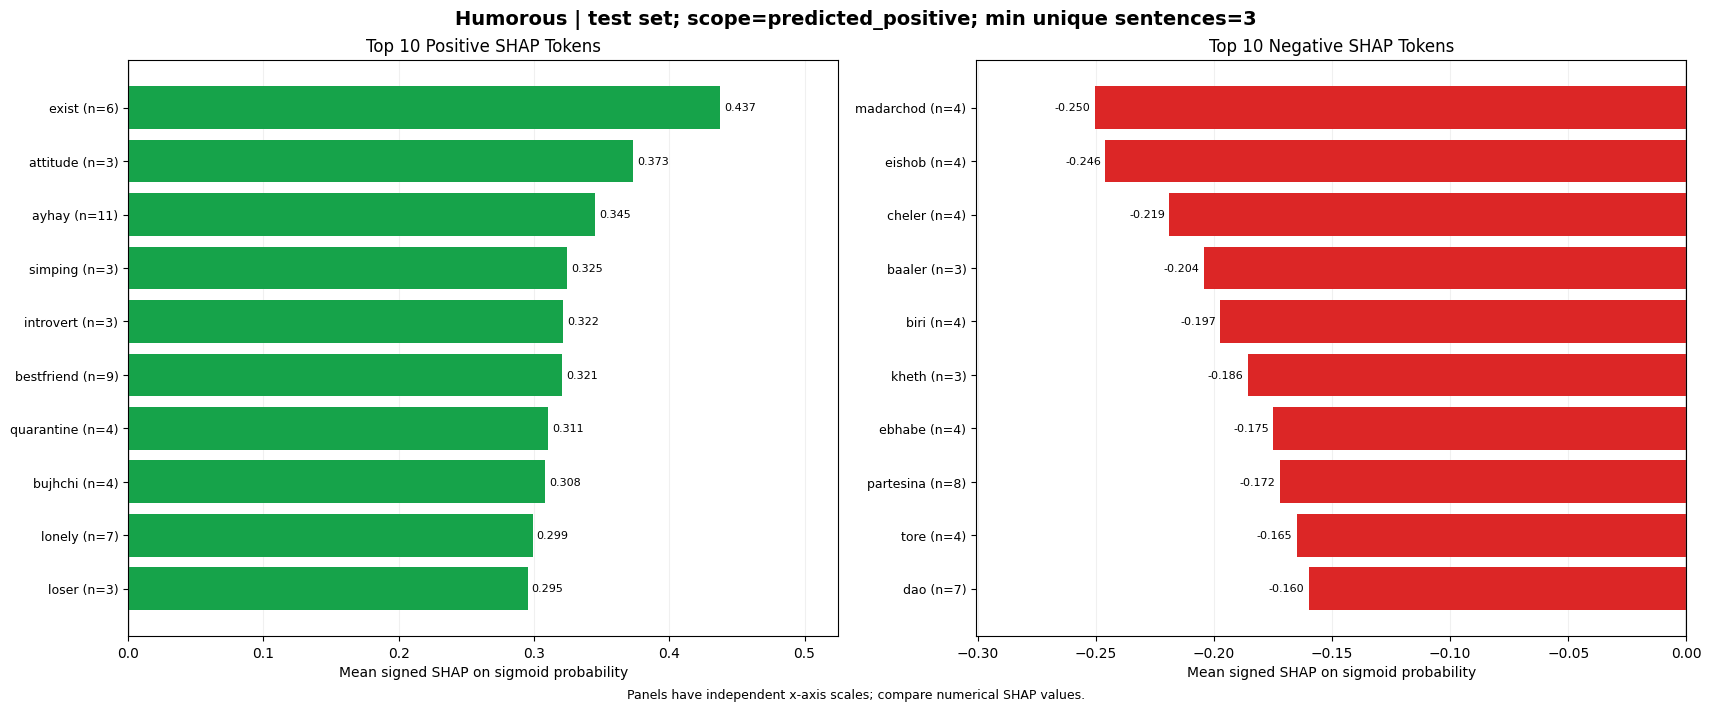

Saved: top10_contributors_humorous.png | positive: 10 | negative: 10


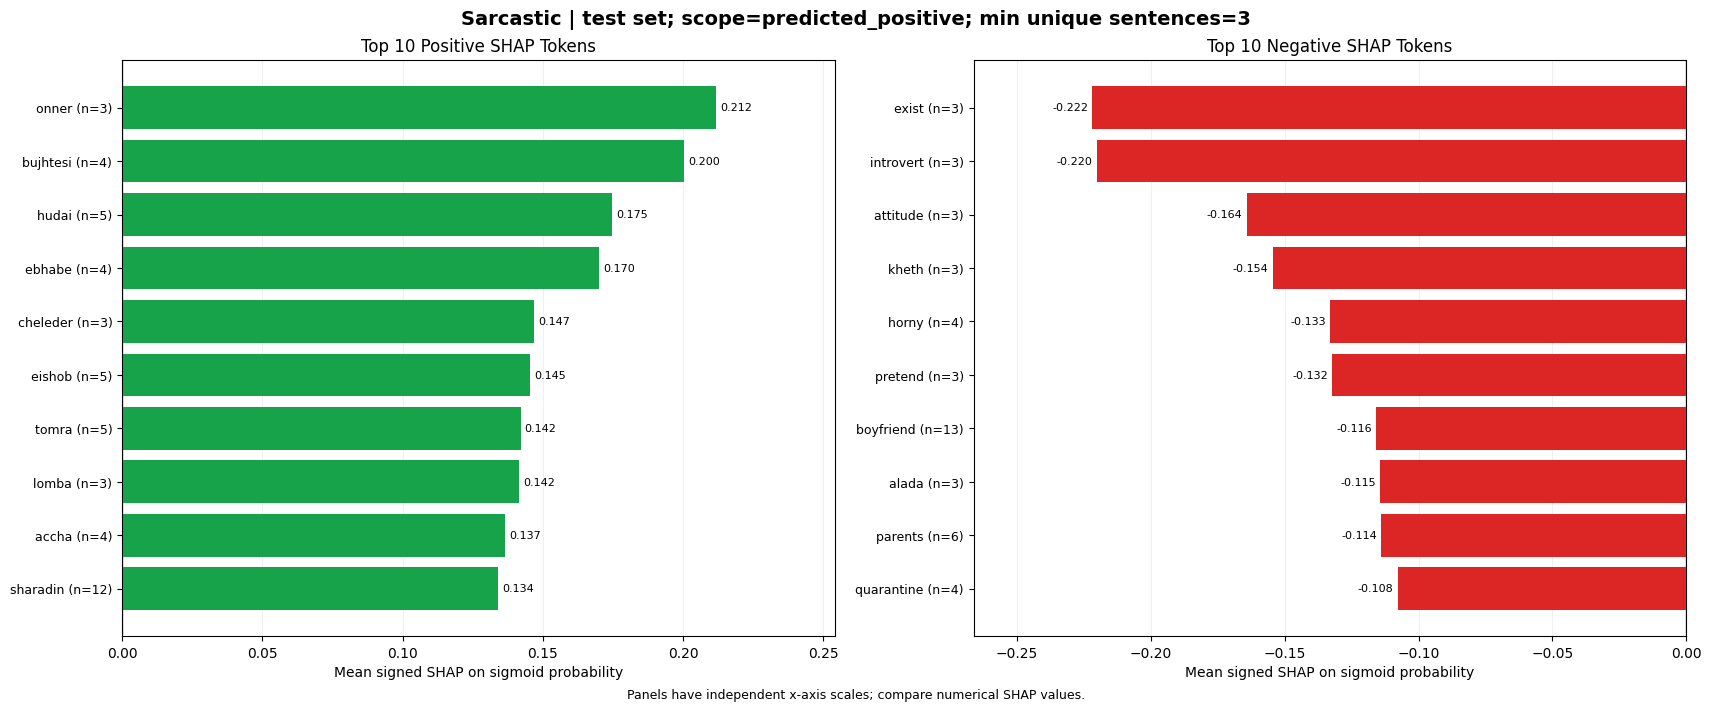

Saved: top10_contributors_sarcastic.png | positive: 10 | negative: 10


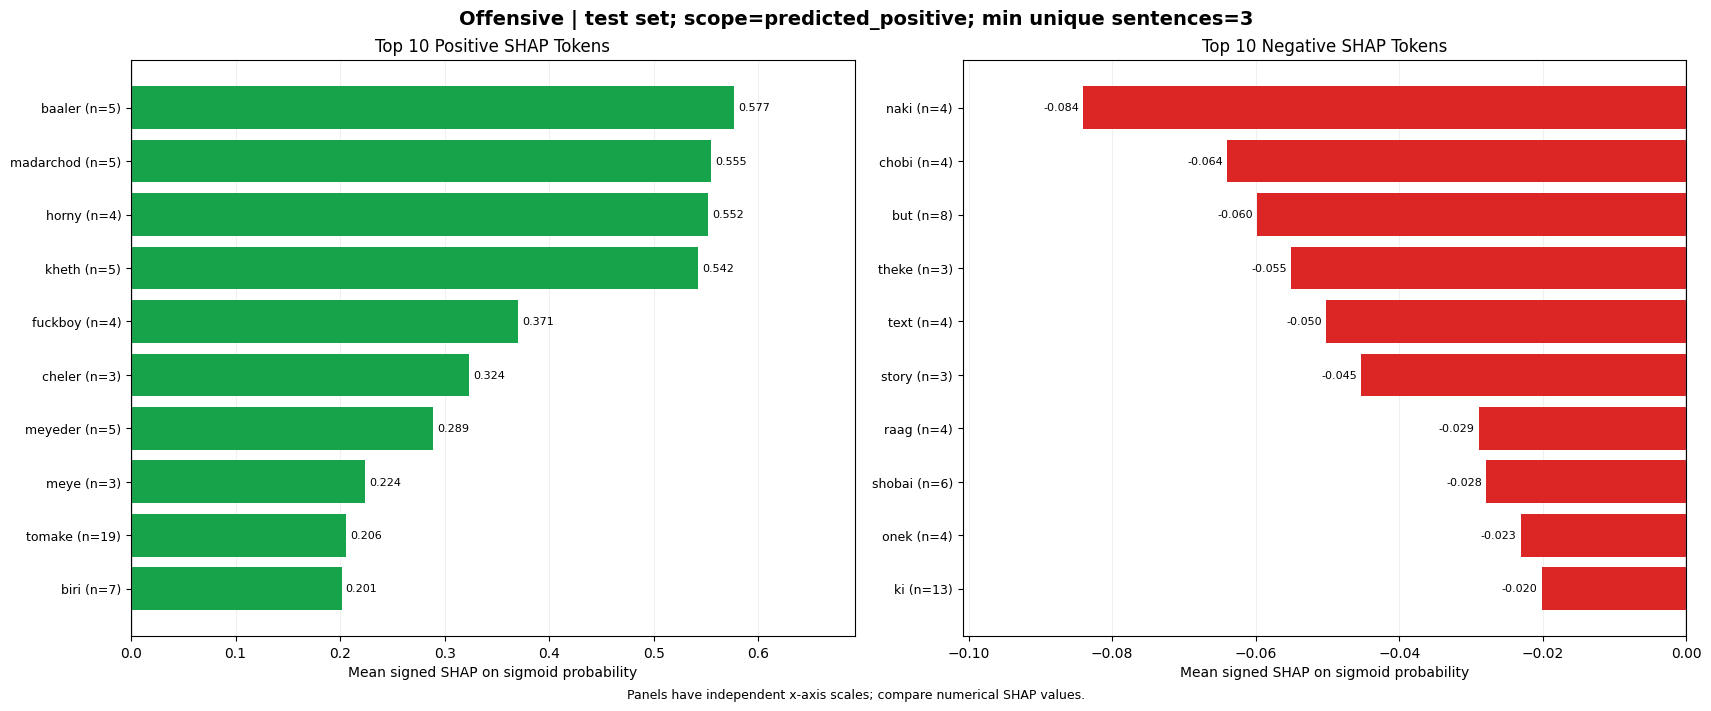

Saved: top10_contributors_offensive.png | positive: 10 | negative: 10


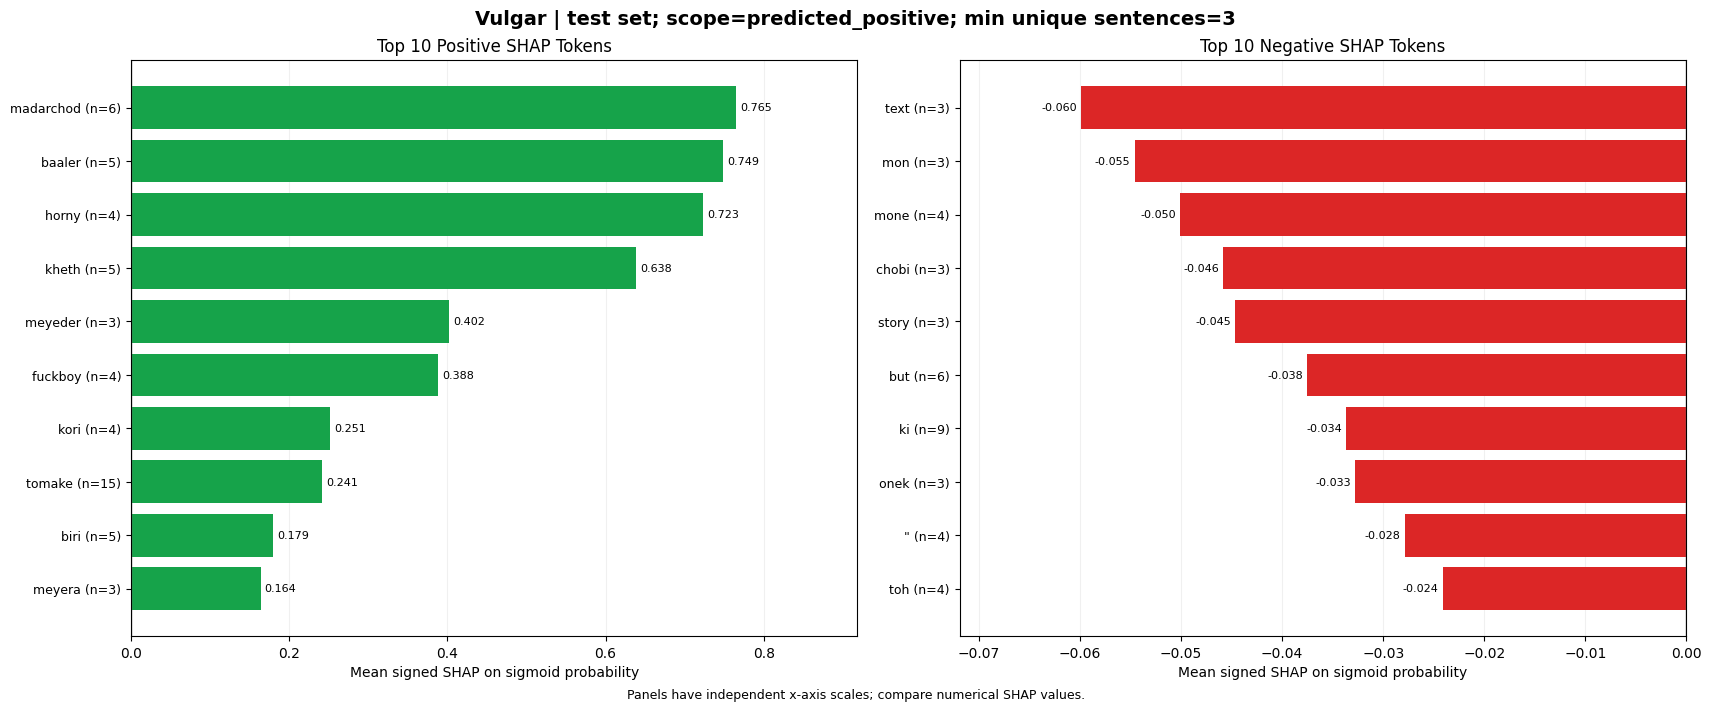

Saved: top10_contributors_vulgar.png | positive: 10 | negative: 10


In [ ]:
# Exactly 4 figures: 1 figure per label; 2 panels in each (top 10 positive, top 10 negative).
# Scope is limited to the held-out test set and labels predicted positive.
CHART_SCOPE = 'predicted_positive'

# Remove obsolete 8-figure outputs if re-running this cell in an older run folder.
for obsolete_pattern in ('top10_positive_*.png', 'top10_negative_*.png'):
    for obsolete_file in FIG_DIR.glob(obsolete_pattern):
        obsolete_file.unlink()

for label in LABELS:
    display_name = label.title()
    eligible = top_tokens[
        top_tokens['target_label'].eq(display_name) &
        top_tokens['analysis_scope'].eq(CHART_SCOPE) &
        top_tokens['unique_sentence_count'].ge(MIN_TOKEN_SENTENCES)
    ].copy()

    positive = (
        eligible[eligible['mean_signed_shap'].gt(0)]
        .nlargest(10, 'mean_signed_shap')
        .sort_values('mean_signed_shap', ascending=True)
    )
    negative = (
        eligible[eligible['mean_signed_shap'].lt(0)]
        .nsmallest(10, 'mean_signed_shap')
        .sort_values('mean_signed_shap', ascending=False)
    )

    # Scale each panel independently so smaller negative attributions remain readable.
    positive_limit = max(float(positive['mean_signed_shap'].max()) if len(positive) else 0.0, 1e-6) * 1.20
    negative_limit = max(float(negative['mean_signed_shap'].abs().max()) if len(negative) else 0.0, 1e-6) * 1.20

    fig, (ax_positive, ax_negative) = plt.subplots(
        1, 2, figsize=(17, 7), constrained_layout=True
    )
    for ax, direction, selected, color in [
        (ax_positive, 'Positive', positive, '#16a34a'),
        (ax_negative, 'Negative', negative, '#dc2626')
    ]:
        if not selected.empty:
            tick_labels = [
                f'{token} (n={n})' for token, n in zip(
                    selected['token'], selected['unique_sentence_count']
                )
            ]
            bars = ax.barh(tick_labels, selected['mean_signed_shap'], color=color)
            ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
            ax.axvline(0, color='gray', lw=1)
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.text(0.5, 0.5, 'No eligible tokens',
                    ha='center', va='center', transform=ax.transAxes)
            ax.set_yticks([])
        ax.set_title(f'Top {len(selected)} {direction} SHAP Tokens')
        ax.set_xlabel('Mean signed SHAP on sigmoid probability')
        ax.grid(axis='x', alpha=0.18)
        ax.set_axisbelow(True)
        if direction == 'Positive':
            ax.set_xlim(0, positive_limit)
        else:
            ax.set_xlim(-negative_limit, 0)

    fig.suptitle(
        f'{display_name} | test set; scope={CHART_SCOPE}; '
        f'min unique sentences={MIN_TOKEN_SENTENCES}',
        fontsize=14, fontweight='bold'
    )
    fig.supxlabel('Panels have independent x-axis scales; compare numerical SHAP values.', fontsize=9)
    output_file = FIG_DIR / f'top10_contributors_{label}.png'
    fig.savefig(output_file, dpi=250, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved:', output_file.name,
          '| positive:', len(positive), '| negative:', len(negative))

# Exactly one output per label (4 total).
assert len(list(FIG_DIR.glob('top10_contributors_*.png'))) == len(LABELS)


## Cell 20 — Sentence-level four-label SHAP heatmap

The heatmap is generated from **the saved wide CSV**, not fabricated numbers. It uses the first H+S test sentence if available, otherwise the first test sentence. Rows are the four model outputs and columns are SHAP text segments, **including punctuation**. If a sentence is very long, the heatmap shows the first 35 segments for readability (the CSV preserves all segments).

**Any sentence on demand:** the next code cell defines `plot_saved_local_shap(sentence_id)` so you can visualize any explained test sentence without recomputing SHAP. To export a PNG for **every** explained sentence, set `EXPORT_ALL_LOCAL_HEATMAPS=True` there (optional; can create many images).

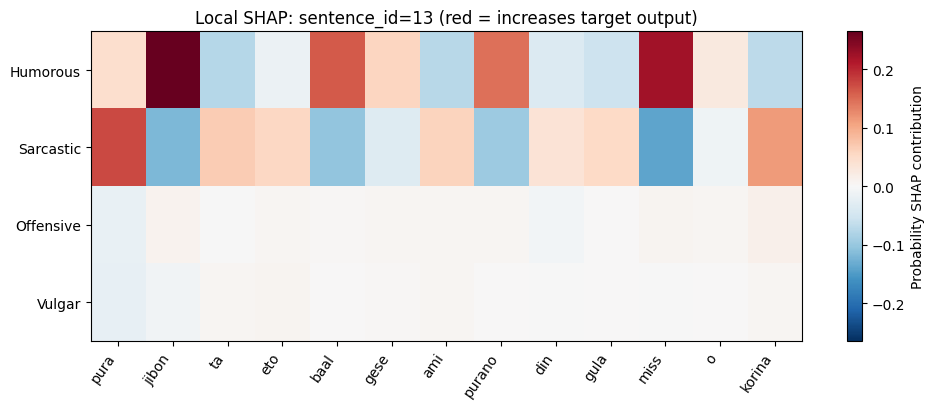

In [ ]:
from matplotlib.colors import TwoSlopeNorm

local_view = shap_wide[shap_wide['sentence_id'].eq(demo_id)].sort_values('token_position')
if local_view.empty:
    raise RuntimeError('Demo sentence was not included in SHAP_LIMIT. Set SHAP_LIMIT=None or select an explained sentence.')
local_view = local_view.head(35)
heat = local_view[SHAP_COLUMNS].to_numpy(dtype=float).T
tokens_for_plot = local_view['token'].astype(str).tolist()
scale = max(float(np.abs(heat).max()), 1e-6)
fig, ax = plt.subplots(figsize=(max(10, len(tokens_for_plot)*0.52), 4.2))
im = ax.imshow(
    heat, cmap='RdBu_r', aspect='auto',
    norm=TwoSlopeNorm(vmin=-scale, vcenter=0.0, vmax=scale)
)
ax.set_xticks(np.arange(len(tokens_for_plot)), labels=tokens_for_plot, rotation=55, ha='right')
ax.set_yticks(np.arange(len(LABELS)), labels=[s.title() for s in LABELS])
ax.set_title(f'Local SHAP: sentence_id={demo_id} (red = increases target output)')
fig.colorbar(im, ax=ax, label='Probability SHAP contribution')
fig.tight_layout()
fig.savefig(FIG_DIR / f'shap_local_heatmap_sentence_{demo_id}.png', dpi=250, bbox_inches='tight')
plt.show()

# Reusable visualization for ANY explained test sentence (no new SHAP calls).
def plot_saved_local_shap(sentence_id, max_tokens=35, save=True, show=True):
    local = shap_wide[shap_wide['sentence_id'].eq(int(sentence_id))].sort_values('token_position')
    if local.empty:
        raise ValueError(f'No saved SHAP rows for sentence_id={sentence_id}; check SHAP_LIMIT.')
    local = local.head(max_tokens)
    matrix = local[SHAP_COLUMNS].to_numpy(dtype=float).T
    cols = local['token'].astype(str).tolist()
    limit = max(float(np.abs(matrix).max()), 1e-6)
    fig, ax = plt.subplots(figsize=(max(10, len(cols) * 0.52), 4.2))
    img = ax.imshow(matrix, cmap='RdBu_r', aspect='auto',
                    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    ax.set_xticks(np.arange(len(cols)), labels=cols, rotation=55, ha='right')
    ax.set_yticks(range(4), labels=[label.title() for label in LABELS])
    ax.set_title(f'Local SHAP sentence_id={sentence_id}')
    fig.colorbar(img, ax=ax, label='Probability SHAP contribution')
    fig.tight_layout()
    filepath = FIG_DIR / 'local_explanations' / f'sentence_{int(sentence_id)}.png'
    if save:
        filepath.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(filepath, dpi=160, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)
    return filepath if save else None

# Examples: plot_saved_local_shap(demo_id)
#           plot_saved_local_shap(int(prediction_df.iloc[5]['sentence_id']))
EXPORT_ALL_LOCAL_HEATMAPS = False    # change to True to save all SHAP sentence heatmaps
if EXPORT_ALL_LOCAL_HEATMAPS:
    for sentence_id in tqdm(shap_sentence_meta['sentence_id'].unique(), desc='Local SHAP heatmaps'):
        plot_saved_local_shap(int(sentence_id), save=True, show=False)


## Cell 21 — Compare Humor vs Sarcasm contributions **within H+S sentences**

For sentences whose **true exact pattern** is `H+S`, display the same tokens' **Humorous** and **Sarcastic** mean SHAP side by side. This is a *comparison of two original model outputs*, **not** the SHAP value of an imaginary combined head. If the held-out subset has zero H+S examples or insufficient token frequency, a message is displayed instead.

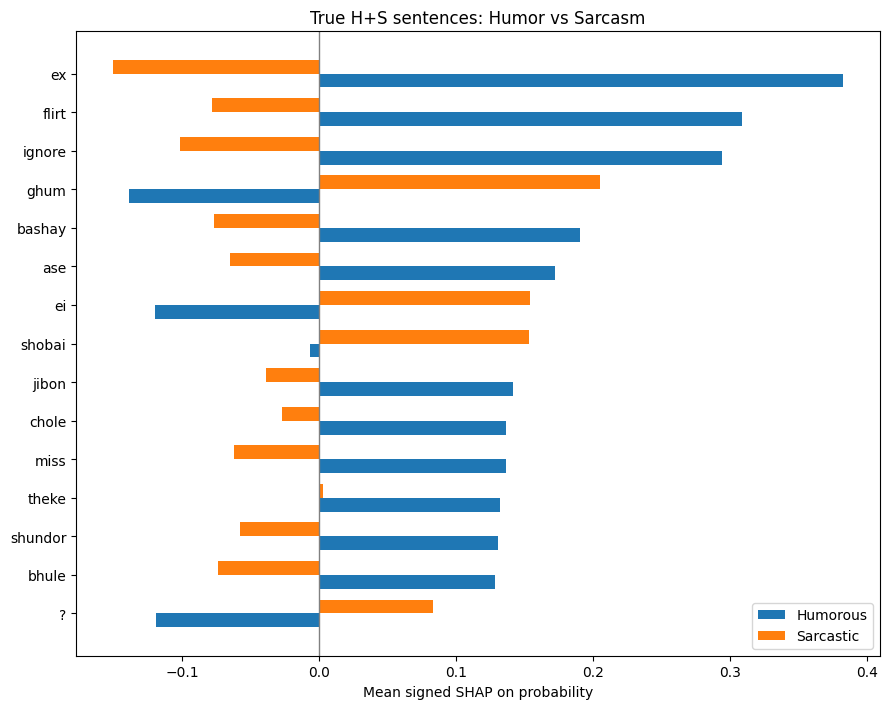

In [ ]:
hs = global_combination.query(
    'combination == "H+S" and analysis_subset == "all_test" and '
    'target_label in ["humorous", "sarcastic"]'
).copy()
hs = hs[hs['n_sentences'] >= MIN_TOKEN_SENTENCES]
if len(hs):
    comparison = hs.pivot_table(
        index='token', columns='target_label', values='mean_SHAP', aggfunc='first'
    ).fillna(0.0)
    for label in ['humorous', 'sarcastic']:
        if label not in comparison.columns:
            comparison[label] = 0.0
    comparison['strength'] = comparison[['humorous', 'sarcastic']].abs().max(axis=1)
    comparison = comparison.nlargest(15, 'strength').sort_values('strength')
    ys = np.arange(len(comparison))
    fig, ax = plt.subplots(figsize=(9, max(4, len(comparison)*0.38 + 1.5)))
    ax.barh(ys - 0.18, comparison['humorous'], height=0.36, label='Humorous')
    ax.barh(ys + 0.18, comparison['sarcastic'], height=0.36, label='Sarcastic')
    ax.axvline(0, color='gray', lw=1)
    ax.set_yticks(ys, labels=comparison.index)
    ax.set(xlabel='Mean signed SHAP on probability', title='True H+S sentences: Humor vs Sarcasm')
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'shap_H_plus_S_label_comparison.png', dpi=250, bbox_inches='tight')
    plt.show()
else:
    print('No H+S tokens meet the frequency rule; inspect shap_global_combination.csv directly.')

## Cell 22 - Optional qualitative linguistic-cue annotation template

A *separate human annotation template* selects high-positive true-positive token instances so you can code sarcasm/discourse markers, laughter, contrast, slang, etc. This is **not** a fourth master SHAP file. Linguistic-cue judgments need contextual human review; SHAP rankings alone do not prove linguistic meaning.


In [ ]:
coding_candidates = (
    shap_long[
        shap_long['prediction_status'].eq('TP') & (shap_long['shap_value'] > 0)
    ][['sentence_id', 'sentence', 'target_label', 'token_position',
       'token', 'shap_value', 'true_combination']]
    .sort_values('shap_value', ascending=False)
    .drop_duplicates(['sentence_id', 'target_label', 'token_position'])
    .head(250)
    .copy()
)
coding_candidates['human_cue_category'] = ''
coding_candidates['annotator_id'] = ''
coding_candidates['qualitative_notes'] = ''
coding_candidates.to_csv(TABLE_DIR / 'linguistic_cue_annotation_template.csv', index=False)
display(coding_candidates.head(10))

,sentence_id,sentence,target_label,token_position,token,shap_value,true_combination,human_cue_category,annotator_id,qualitative_notes
54999,4172,Uff peyaj chilte chilte horny hoye gese,vulgar,4,horny,0.909974,V,,,
62978,8880,Friend list er ordhek depressed and baki ordhe...,vulgar,8,horny,0.889010,H+V,,,
51446,2043,manush olpo te prem e pore jai and ami olpo te...,vulgar,11,horny,0.847617,V,,,
50894,1658,baaler facebook bhalolagena shudhu tomake bhal...,vulgar,0,baaler,0.826672,H+V,,,
51433,2042,baal chobi ta fati gese,vulgar,3,fati,0.754049,V,,,
61975,8163,"Fuckboi101- Nari amr nesha, Ar virgin khuja am...",vulgar,0,Fuckboi101,0.726069,S+V,,,
51026,1756,madarchod amar 500 taka na diye kylie k taka f...,vulgar,0,madarchod,0.726053,O+V,,,
50725,1550,baaler nutun chathead open hole ager ta seen h...,vulgar,0,baaler,0.722027,V,,,
35650,2075,ami kori business tumi koro bitchness ahahaaha...,offensive,5,bitchness,0.707724,O,,,
52827,3038,Madarchod but mon ta bhalo,vulgar,0,Madarchod,0.706450,H+V,,,


## Cell 23 - Validation, reproducibility readme, and downloadable ZIP

Final SHAP CSV set: **`sentence_level_shap.csv`** (10 columns; predicted-positive only), **`shap_local_wide.csv`** (four heads; full archive), **`label_wise_top_tokens.csv`** (12 columns, 6 scopes). The ZIP also contains `test_predictions.csv`, evaluation CSVs (with binary accuracy and overall exact-match accuracy), four label-wise figures (each with a positive and negative panel), optional heatmaps, split CSVs, and methodology metadata. The fine-tuned model checkpoint remains saved in the run-specific Drive folder, **not** zipped (to keep the results ZIP smaller).


In [ ]:
import zipfile

readme = f"""# MixSarc / BanglishBERT weighted-BCE + SHAP
Run ID: {RUN_ID}
Dataset: {DATASET_ID}; encoder: {MODEL_ID}
Labels: {LABELS} (four sigmoid outputs; overlaps permitted)
Split: iterative multi-label stratification 70/15/15 after duplicate audit
Training: weighted BCE; positive weights from train only, square-root ratio capped at {POS_WEIGHT_CAP}
Max epochs: {NUM_EPOCHS}; early stopping patience: {EARLY_STOPPING_PATIENCE}
Checkpoint: highest VALIDATION Macro-AP
Thresholds: optimize validation per-label F1 only; no test-based selection
Accuracy: per-label binary accuracy; overall accuracy = exact-match/subset accuracy
Label decision accuracy = 1 - Hamming loss (distinct from exact-match)
SHAP: word/punctuation masker, sigmoid PROBABILITY, all 4 outputs for each explained test sentence
Explained test sentences: {len(explain_df)} / {len(prediction_df)}
PRIMARY SHAP CSVs:
  tables/shap_local_wide.csv               - all SHAP output heads per token
  tables/sentence_level_shap.csv            - predicted-positive label heads ONLY, exactly 10 columns
  tables/label_wise_top_tokens.csv          - label-token-scope rankings, exactly 12 columns
Token summary means and counts: per token OCCURRENCE (no repeated-token collapse).
CSV rank: descending mean_abs_shap within target_label + analysis_scope.
Scopes: predicted_positive (main charts), all_test, actual_positive, TP, FP, FN.
Token chart direction: positive and negative ranks by mean_signed_shap in separate panels of one figure per label.
Minimum distinct sentence support for plotting: {MIN_TOKEN_SENTENCES}.
Exactly four core top-token figures: one per label; two panels (Top 10 positive and Top 10 negative).
Zero SHAP occurrence: counted in occurrence denominator, not in positive/negative counts.
A label with no predicted positives is absent from sentence_level_shap.csv;
it remains explainable in shap_local_wide.csv.
Optional: H+S comparison in memory; SHAP additivity QA in JSON.
Linguistic attributions are model- and masker-dependent, not causal proof.
Rare combinations and low-support tokens require cautious interpretation.
"""
(ROOT / 'METHODOLOGY_README.txt').write_text(readme, encoding='utf-8')

assert (TABLE_DIR / 'shap_local_wide.csv').exists()
assert (TABLE_DIR / 'sentence_level_shap.csv').exists()
assert (TABLE_DIR / 'label_wise_top_tokens.csv').exists()
assert (TABLE_DIR / 'test_predictions.csv').exists()
assert (ROOT / 'thresholds.json').exists()
assert shap_wide[SHAP_COLUMNS].notna().all().all()
assert sentence_level.columns.tolist() == SENTENCE_LEVEL_COLUMNS
assert top_tokens.columns.tolist() == TOKEN_SUMMARY_COLUMNS
assert np.isclose(float(overall_df.iloc[0]['accuracy']), accuracy_score(y_true, y_pred))
for label in LABELS:
    assert (FIG_DIR / f'top10_contributors_{label}.png').exists()
assert len(list(FIG_DIR.glob('top10_contributors_*.png'))) == 4

zip_path = ROOT.parent / f'MixSarc_WeightedBCE_SHAP_results_{RUN_ID}.zip'
include_dirs = [DATA_DIR, TABLE_DIR, FIG_DIR]
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for directory in include_dirs:
        for file in sorted(directory.rglob('*')):
            if file.is_file():
                zf.write(file, file.relative_to(ROOT))
    for file in [ROOT/'run_config.json', ROOT/'trained_model_metadata.json',
                 ROOT/'thresholds.json', ROOT/'shap_sentence_metadata.json',
                 ROOT/'METHODOLOGY_README.txt']:
        if file.exists():
            zf.write(file, file.relative_to(ROOT))

print('Results ZIP:', zip_path)
print('Size (MB):', round(zip_path.stat().st_size / 1_000_000, 2))
print('Saved model directory:', MODEL_DIR)
if DOWNLOAD_RESULTS_ZIP:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except ImportError:
        print('Download the ZIP from the runtime file browser:', zip_path)


Results ZIP: /content/drive/MyDrive/MixSarc_WeightedBCE_SHAP/MixSarc_WeightedBCE_SHAP_results_20261016T101524Z.zip
Size (MB): 4.04
Saved model directory: /content/drive/MyDrive/MixSarc_WeightedBCE_SHAP/20261016T101524Z/best_model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## End - What to report in the research paper

1. **Model and data:** number of clean samples after audit, train/validation/test overlap distributions, exact train-derived positive weights, 15-epoch maximum, early stopping patience 3, best validation Macro-AP checkpoint.
2. **Classification:** per-label Precision, Recall, F1, **accuracy** and AP; overall **accuracy = exact-match**, label-decision accuracy, Macro/Micro/Samples-F1, Hamming loss; exact-combination and pair-co-occurrence metrics. Do **not** interpret high per-label accuracy alone as success on rare Offensive/Vulgar classes.
3. **Local explanations:** `sentence_level_shap.csv` provides each predicted-positive output's token signed/magnitude scores with sentence, gold/predicted binary labels and predicted probability. Use `shap_local_wide.csv` for all outputs, including missed true positives (FN).
4. **Global token explanations:** `label_wise_top_tokens.csv` contains occurrence and unique-sentence counts, positive/negative rates and signs, and rankings by absolute SHAP for each label and scope; four label-wise figures (each with positive/negative Top 10 panels) use **signed mean SHAP** in the `predicted_positive` scope.
5. **Combined-label analysis:** H+S and other combinations are **subsets of the same four-output model**, not additional classes. The optional H+S comparison uses separately attributed outputs.
6. **Interpretation:** model-specific cue hypotheses should be verified by contextual human annotation, support counts, and analysis of false positives/false negatives.

**References:** [Dataset](https://huggingface.co/datasets/ajwad-abrar/MixSarc) | [Paper](https://arxiv.org/abs/2602.21608) | [BanglishBERT](https://huggingface.co/csebuetnlp/banglishbert) | [SHAP Text masker](https://shap.readthedocs.io/en/latest/generated/shap.maskers.Text.html) | [iterative stratification](https://github.com/trent-b/iterative-stratification)
